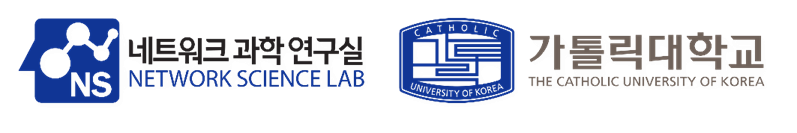

# Week 7: Attentive GNNs

# 0. Setup

In [1]:
INSTALL_DEPENDENCIES = False

if INSTALL_DEPENDENCIES:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "torch-geometric"])

In [2]:
import math, random, copy, warnings, contextlib, io
warnings.filterwarnings("ignore")
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.datasets import Planetoid, WebKB, IMDB

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(0)
ROOT = "./data"
COLORS = {'MLP': '#9a9a9a', 'GCN': '#2a78d6', 'GAT': '#eb6834', 'GATv2': '#1baf7a', 'SuperGAT': '#4a3aa7',
          'FAGCN': '#e34948', 'HAN': '#0A047A'}

Device: cuda


## 0.1. Message passing on an edge list

A graph is stored as `edge_index` of shape $[2, E]$: column $e$ is an edge $j \to i$ with **source** $j$ = `edge_index[0, e]` (the neighbour that sends a message) and target $i$ = `edge_index[1, e]` (the node that is updated). This is PyG's convention; an undirected graph stores both directions.

Every layer of this notebook follows the same three steps:
1. compute one score per edge from the two endpoints,
2. normalise the scores over the incoming edges of every target node (softmax for attention),
3. aggregate: sum the weighted messages into the target node.

Steps 2 and 3 need two helpers, `edge_softmax` and `scatter_sum`. Working on the $E$ edges instead of an $N\times N$ matrix keeps memory linear in the number of edges.

In [3]:
def add_self_loops(edge_index, N):
    """Append the self-loops (i, i): the attention of GAT runs over N(i) ∪ {i}."""
    loops = torch.arange(N, device=edge_index.device)
    return torch.cat([edge_index, torch.stack([loops, loops])], dim=1)

def degree(index, N):
    """Number of edges per node; with index = edge_index[1] this is the in-degree."""
    return torch.zeros(N, device=index.device).index_add_(0, index, torch.ones(index.numel(), device=index.device))

def scatter_sum(values, index, N):
    """out[i] = Σ_{e : index[e] = i} values[e]   (the AGGREGATE step of message passing)."""
    out = torch.zeros((N,) + values.shape[1:], device=values.device, dtype=values.dtype)
    return out.index_add_(0, index, values)

def edge_softmax(scores, dst, N):
    """α_e = exp(s_e) / Σ_{e': dst[e'] = dst[e]} exp(s_e'): softmax over the incoming edges of every target node.
    scores: [E] or [E, heads]. The maximum of every node is subtracted first (numerically stable, same result)."""
    idx = dst.view(-1, *([1] * (scores.dim() - 1))).expand_as(scores)
    m = torch.full((N,) + scores.shape[1:], -float('inf'), device=scores.device)
    m = m.scatter_reduce(0, idx, scores.detach(), reduce='amax')
    e = (scores - m[dst]).exp()
    return e / scatter_sum(e, dst, N)[dst]

def glorot_(t):
    """Glorot / Xavier uniform initialisation U(-a, a), a = sqrt(6 / (fan_in + fan_out)) (PyG's `glorot`)."""
    a = math.sqrt(6.0 / (t.size(-2) + t.size(-1)))
    with torch.no_grad():
        return t.uniform_(-a, a)

## 0.2. Dataset: Cora

Cora is a citation network (papers, citations, bag-of-words features, 7 topics) with the standard semi-supervised split of 20 labelled nodes per class. As in the GAT paper, the features are row-normalised.

In [4]:
with contextlib.redirect_stderr(io.StringIO()):           
    dataset = Planetoid(ROOT, "Cora")
data = dataset[0]
N, num_features, num_classes = data.num_nodes, dataset.num_features, dataset.num_classes

X = data.x.to(device)
X = X / X.sum(dim=1, keepdim=True).clamp(min=1)            # row-normalised features
y = data.y.to(device)
edge_index = data.edge_index.to(device)                    # [2, E]: row 0 = source j, row 1 = target i
split = tuple(m.to(device) for m in (data.train_mask, data.val_mask, data.test_mask))

src, dst = edge_index
deg = degree(dst, N)
print(f'Dataset: {dataset}')
print('-------------------')
print(f'Number of nodes: {N}')
print(f'Number of edges: {edge_index.size(1)} (directed) = {edge_index.size(1) // 2} undirected')
print(f'Number of features: {num_features}')
print(f'Number of classes: {num_classes}')
print(f'Train / Val / Test nodes: {int(split[0].sum())} / {int(split[1].sum())} / {int(split[2].sum())}')
print(f'Isolated nodes: {int((deg == 0).sum())} | Self-loops: {int((src == dst).sum())} | Mean degree: {deg.mean():.2f}')
print(f'Edge homophily (share of edges inside a class): {(y[src] == y[dst]).float().mean():.3f}')

Dataset: Cora()
-------------------
Number of nodes: 2708
Number of edges: 10556 (directed) = 5278 undirected
Number of features: 1433
Number of classes: 7
Train / Val / Test nodes: 140 / 500 / 1000
Isolated nodes: 0 | Self-loops: 0 | Mean degree: 3.90
Edge homophily (share of edges inside a class): 0.810


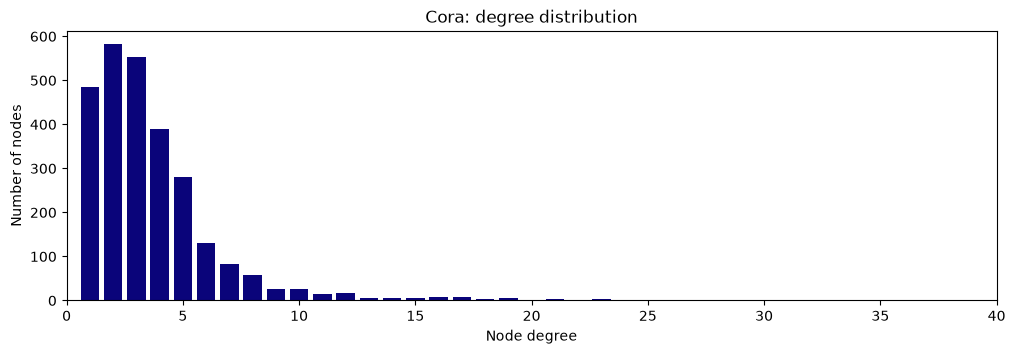

In [5]:
numbers = Counter(deg.long().tolist())
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(list(numbers.keys()), list(numbers.values()), color='#0A047A')
ax.set(xlabel='Node degree', ylabel='Number of nodes', xlim=(0, 40), title='Cora: degree distribution')
plt.show()

## 0.3. Training and evaluation

Full-batch training with Adam and early stopping on the validation accuracy; the weights of the best validation epoch are restored. If a model defines `aux_loss()` (SuperGAT's self-supervised loss), it is added to the cross-entropy. `benchmark` repeats the training for 3 seeds and stores the test accuracies in `RESULTS`.

In [6]:
def accuracy(pred, labels):
    return (pred == labels).float().mean().item()

def train_model(model, inputs, split=split, labels=y, epochs=500, lr=0.005, weight_decay=5e-4, patience=100,
                optimizer=None, verbose=False, log_every=50):
    """Train model(*inputs) on split = (train, val, test) masks. Returns (best val acc, test acc at that epoch)."""
    tr, va, te = split
    model = model.to(device)
    if optimizer is None:
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_val, best_val_loss, best_test, bad, best_state = -1., float('inf'), 0., 0, None
    for epoch in range(1, epochs + 1):
        # Training
        model.train()
        optimizer.zero_grad()
        out = model(*inputs)
        loss = F.cross_entropy(out[tr], labels[tr])
        if hasattr(model, 'aux_loss'):
            loss = loss + model.aux_loss()                 # e.g. the self-supervised edge loss of SuperGAT
        loss.backward()
        optimizer.step()

        # Validation / test
        model.eval()
        with torch.no_grad():
            out = model(*inputs)
            val_loss = F.cross_entropy(out[va], labels[va]).item()
            pred = out.argmax(dim=1)
            train_acc, val_acc, test_acc = (accuracy(pred[m], labels[m]) for m in (tr, va, te))
        if val_acc > best_val or (val_acc == best_val and val_loss < best_val_loss):
            best_val, best_val_loss, best_test, bad = val_acc, val_loss, test_acc, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
        if verbose and (epoch == 1 or epoch % log_every == 0):
            print(f'Epoch {epoch:>3} | Train Loss: {loss.item():.3f} | Train Acc: {train_acc*100:6.2f}% | '
                  f'Val Loss: {val_loss:.3f} | Val Acc: {val_acc*100:6.2f}%')
        if bad >= patience:
            break
    model.load_state_dict(best_state)
    if verbose:
        print(f'>> Stopped at epoch {epoch} | Best Val Acc: {best_val*100:.2f}% | Test Acc: {best_test*100:.2f}%')
    return best_val, best_test

RESULTS = {}   

def benchmark(name, make_model, inputs=None, seeds=(0, 1, 2), **train_kwargs):
    """Train a fresh make_model() for every seed on Cora; store and print the mean ± std test accuracy."""
    accs = []
    for seed in seeds:
        set_seed(seed)
        accs.append(train_model(make_model(), inputs if inputs is not None else (X, edge_index), **train_kwargs)[1])
    RESULTS[name] = np.array(accs)
    print(f'{name:<22} | Test Acc: {np.mean(accs)*100:.2f} ± {np.std(accs)*100:.2f}')

# 1. Recap: all neighbours are equally important

A GCN layer computes a message $W h_j$ for every neighbour and sums the messages with fixed weights:

$$h_i' = \sigma\Big(\sum_{j\in\mathcal N(i)\cup\{i\}} \frac{1}{\sqrt{d_i d_j}}\, W h_j\Big),\qquad d_i = |\mathcal N(i)|+1 .$$

The weight of neighbour $j$ depends only on the two degrees, never on what $j$ says. The MLP ignores the graph and is our lower bound.

In [7]:
class MLP(nn.Module):
    """2-layer MLP on the node features only (no graph)."""
    def __init__(self, in_dim, hidden_dim, out_dim, dropout=0.5):
        super().__init__()
        self.lin1, self.lin2, self.dropout = nn.Linear(in_dim, hidden_dim), nn.Linear(hidden_dim, out_dim), dropout

    def forward(self, x, edge_index=None):
        x = F.dropout(x, self.dropout, self.training)
        x = F.dropout(F.relu(self.lin1(x)), self.dropout, self.training)
        return self.lin2(x)

class GCNLayer(nn.Module):
    """h_i' = Σ_{j ∈ N(i) ∪ {i}} W h_j / sqrt(d_i d_j)  on the edge list."""
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.lin = nn.Linear(in_dim, out_dim, bias=False)
        self.bias = nn.Parameter(torch.zeros(out_dim))

    def forward(self, x, edge_index):
        N = x.size(0)
        src, dst = add_self_loops(edge_index, N)
        d = degree(dst, N)
        # ★ KEY: The weight of an edge is fixed by the degrees: every neighbour is treated the same way.
        w = (d[src] * d[dst]).rsqrt()
        return scatter_sum(w[:, None] * self.lin(x)[src], dst, N) + self.bias

class GCN(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim, dropout=0.5):
        super().__init__()
        self.conv1, self.conv2, self.dropout = GCNLayer(in_dim, hidden_dim), GCNLayer(hidden_dim, out_dim), dropout

    def forward(self, x, edge_index):
        x = F.dropout(x, self.dropout, self.training)
        x = F.dropout(F.relu(self.conv1(x, edge_index)), self.dropout, self.training)
        return self.conv2(x, edge_index)

In [8]:
benchmark('MLP', lambda: MLP(num_features, 64, num_classes), lr=0.01)
benchmark('GCN', lambda: GCN(num_features, 64, num_classes), lr=0.01)

MLP                    | Test Acc: 58.80 ± 0.24
GCN                    | Test Acc: 82.57 ± 0.26


# 2. Graph Attention Networks (GAT)
## 2.1. One attention head

Use the 4-node graph (edges 1–3, 1–4, 2–3, 2–4, plus a self-loop on every node), random features $h_i\in\mathbb R^3$, a weight matrix $W\in\mathbb R^{2\times 3}$ and an attention vector $\mathbf a\in\mathbb R^{4}$:

1. Linear transformation: $z_i = W h_i$ and the pair score $\mathbf a^\top[z_i\,\|\,z_j]$,
2. Activation: $e_{ij} = \mathrm{LeakyReLU}(\mathbf a^\top[z_i\,\|\,z_j])$ (negative slope 0.2),
3. Masking + softmax: $e_{ij}=-\infty$ when $j\notin\mathcal N(i)$, then $\alpha_{ij}=\exp(e_{ij})/\sum_{k\in\mathcal N(i)}\exp(e_{ik})$, so every row sums to 1,
4. Aggregation: $h_i' = \sum_j \alpha_{ij}\, z_j$ (followed by a non-linearity $\sigma$ in a real layer).

In [9]:
# Adjacency matrix WITH self-loops
A_toy = torch.tensor([[1, 0, 1, 1],
                      [0, 1, 1, 1],
                      [1, 1, 1, 0],
                      [1, 1, 0, 1]], dtype=torch.float)
set_seed(0)
h_toy = torch.randn(4, 3)               # input features h_i ∈ R^3
W_toy = torch.randn(2, 3)               # shared linear transformation W: R^3 -> R^2
a_toy = torch.randn(4)                  # attention vector a ∈ R^(2F') = R^4

def show(M, title):
    print(title)
    for i, row in enumerate(M):
        print(f'   node {i + 1}: ' + '  '.join(f'{v:7.3f}' if torch.isfinite(v) else '   -inf' for v in row))

z_toy = h_toy @ W_toy.t()                                         # 1) z_i = W h_i
pair = (z_toy @ a_toy[:2])[:, None] + (z_toy @ a_toy[2:])[None, :]  #    aᵀ[z_i || z_j] for all pairs (i, j)
e_toy = F.leaky_relu(pair, negative_slope=0.2)                    # 2) e_ij
masked = e_toy.masked_fill(A_toy == 0, float('-inf'))             # 3) mask the non-edges ...
alpha_toy = torch.softmax(masked, dim=1)                          #    ... and normalise every row
h_new = alpha_toy @ z_toy                                         # 4) h_i' = Σ_j α_ij z_j

show(e_toy, 'Attention scores e_ij (every pair)')
show(masked, 'Masked attention scores')
show(alpha_toy, 'Attention coefficients α_ij')
print('Row sums:', [round(v, 3) for v in alpha_toy.sum(dim=1).tolist()])
show(h_new, "Aggregated features h_i' = Σ_j α_ij W h_j")

Attention scores e_ij (every pair)
   node 1:  -0.067    0.243   -0.087    0.406
   node 2:  -0.099    0.087   -0.119    0.250
   node 3:  -0.113    0.013   -0.133    0.176
   node 4:  -0.099    0.082   -0.119    0.245
Masked attention scores
   node 1:  -0.067     -inf   -0.087    0.406
   node 2:    -inf    0.087   -0.119    0.250
   node 3:  -0.113    0.013   -0.133     -inf
   node 4:  -0.099    0.082     -inf    0.245
Attention coefficients α_ij
   node 1:   0.279    0.000    0.273    0.448
   node 2:   0.000    0.334    0.272    0.393
   node 3:   0.321    0.364    0.315    0.000
   node 4:   0.277    0.332    0.000    0.391
Row sums: [1.0, 1.0, 1.0, 1.0]
Aggregated features h_i' = Σ_j α_ij W h_j
   node 1:   0.334   -0.158
   node 2:   0.107    0.006
   node 3:   0.579   -0.306
   node 4:  -0.067    0.066


The same coefficients on the edge list: one score per existing edge, then `edge_softmax` over the incoming edges of every node. The $-\infty$ entries are never computed.

In [10]:
toy_edges = A_toy.nonzero().t().flip(0)               # nonzero() gives (i, j); store row 0 = source j, row 1 = target i
toy_src, toy_dst = toy_edges
e_edges = F.leaky_relu((z_toy @ a_toy[:2])[toy_dst] + (z_toy @ a_toy[2:])[toy_src], 0.2)
alpha_edges = edge_softmax(e_edges, toy_dst, 4)
print(f'{toy_edges.size(1)} edges instead of 16 pairs | '
      f'max |α(dense) - α(edge list)| = {(alpha_toy[toy_dst, toy_src] - alpha_edges).abs().max().item():.1e}')

12 edges instead of 16 pairs | max |α(dense) - α(edge list)| = 3.0e-08


Multi-head attention: repeat the three steps with $K$ independent $(W^k, \mathbf a^k)$ and either concatenate the $K$ results (hidden layers, $K F'$ features) or average them (output layer, $F'$ features).

In [11]:
K = 3
W_heads, a_heads = torch.randn(K, 2, 3), torch.randn(K, 4)
head_outputs = []
for k in range(K):
    zk = h_toy @ W_heads[k].t()
    ek = F.leaky_relu((zk @ a_heads[k, :2])[:, None] + (zk @ a_heads[k, 2:])[None, :], 0.2)
    head_outputs.append(torch.softmax(ek.masked_fill(A_toy == 0, float('-inf')), dim=1) @ zk)

concat = torch.cat(head_outputs, dim=1)          # h_i = ||_k h_i^k        (hidden layers)
average = torch.stack(head_outputs).mean(dim=0)  # h_i = (1/K) Σ_k h_i^k   (output layer)
print(f'one head: {tuple(head_outputs[0].shape)} | concatenation: {tuple(concat.shape)} | average: {tuple(average.shape)}')

one head: (4, 2) | concatenation: (4, 6) | average: (4, 2)


## 2.2. GAT layer: dense (masked $N\times N$) vs. edge list

`DenseGATLayer` is a direct translation: it builds the full $N\times N$ score matrix, which needs $O(N^2)$ memory per head (7.3 million scores for Cora, 389 million for PubMed).

`GATLayer` computes one score per edge instead. Splitting $\mathbf a = [\mathbf a_1\,\|\,\mathbf a_2]$,

$$\mathbf a^\top[W h_i\,\|\,W h_j] = \underbrace{\mathbf a_1^\top W h_i}_{\text{target } i} + \underbrace{\mathbf a_2^\top W h_j}_{\text{source } j},$$

so each node needs only two scalars per head, which are added along the edges. Both layers must give the same output.

In [12]:
class DenseGATLayer(nn.Module):
    """One-head GAT layer: N × N scores, -inf on the non-edges, softmax over each row."""
    def __init__(self, in_dim, out_dim, negative_slope=0.2):
        super().__init__()
        self.W = nn.Linear(in_dim, out_dim, bias=False)
        self.a_dst = nn.Parameter(glorot_(torch.empty(1, out_dim)))   # a_1 (multiplies W h_i)
        self.a_src = nn.Parameter(glorot_(torch.empty(1, out_dim)))   # a_2 (multiplies W h_j)
        self.negative_slope = negative_slope

    def forward(self, x, adj):                 # adj[i, j] = 1 if j -> i, self-loops included
        z = self.W(x)
        e = F.leaky_relu(z @ self.a_dst.t() + (z @ self.a_src.t()).t(), self.negative_slope)   # e[i, j]
        alpha = torch.softmax(e.masked_fill(adj == 0, float('-inf')), dim=1)
        return alpha @ z

class GATLayer(nn.Module):
    """GAT layer (Veličković et al., ICLR 2018) with K heads on the edge list:
         e_ij = LeakyReLU(a_1ᵀ W h_i + a_2ᵀ W h_j)          (= LeakyReLU(aᵀ [W h_i || W h_j]))
         α_ij = softmax_{j ∈ N(i) ∪ {i}} (e_ij)
         h_i' = ||_k Σ_j α_ij^k W^k h_j   (concat)   or   (1/K) Σ_k Σ_j α_ij^k W^k h_j   (average)"""
    def __init__(self, in_dim, out_dim, heads=1, concat=True, dropout=0.6, negative_slope=0.2, self_loops=True):
        super().__init__()
        self.heads, self.out_dim, self.concat = heads, out_dim, concat
        self.dropout, self.negative_slope, self.self_loops = dropout, negative_slope, self_loops
        self.W = nn.Linear(in_dim, heads * out_dim, bias=False)       # the K matrices W^k, stacked
        self.a_dst = nn.Parameter(torch.empty(heads, out_dim))        # a_1^k: target (query) half of a^k
        self.a_src = nn.Parameter(torch.empty(heads, out_dim))        # a_2^k: source (key) half of a^k
        self.bias = nn.Parameter(torch.zeros(heads * out_dim if concat else out_dim))
        glorot_(self.W.weight); glorot_(self.a_dst); glorot_(self.a_src)

    def forward(self, x, edge_index):
        N = x.size(0)
        if self.self_loops:
            edge_index = add_self_loops(edge_index, N)
        src, dst = edge_index
        z = self.W(x).view(N, self.heads, self.out_dim)               # W^k h for every node and head
        # ★ KEY: aᵀ[W h_i || W h_j] = a_1ᵀ W h_i + a_2ᵀ W h_j: two scalars per node, added along every edge.
        e = F.leaky_relu((z * self.a_dst).sum(-1)[dst] + (z * self.a_src).sum(-1)[src], self.negative_slope)
        # ★ KEY: Softmax over the incoming edges of each node = the masked row softmax.
        alpha = edge_softmax(e, dst, N)                               # [E, heads]
        self.edge_index, self.alpha = edge_index, alpha.detach()      # kept for the analysis below
        alpha = F.dropout(alpha, self.dropout, self.training)         # attention dropout 
        out = scatter_sum(alpha.unsqueeze(-1) * z[src], dst, N)       # Σ_j α_ij W h_j for every head
        out = out.reshape(N, -1) if self.concat else out.mean(dim=1)
        return out + self.bias

    def extra_repr(self):
        return f'heads={self.heads}, concat={self.concat}'

In [13]:
from torch_geometric.nn import GATConv

# Dense vs. edge list (one head, same weights, no dropout)
set_seed(0)
edge_layer = GATLayer(num_features, 8, heads=1, dropout=0.0).to(device)
dense_layer = DenseGATLayer(num_features, 8).to(device)
with torch.no_grad():
    dense_layer.W.weight.copy_(edge_layer.W.weight)
    dense_layer.a_dst.copy_(edge_layer.a_dst)
    dense_layer.a_src.copy_(edge_layer.a_src)
adj = torch.eye(N, device=device)
adj[dst, src] = 1.0                                       # adj[i, j] = 1 if j -> i
diff = (dense_layer(X, adj) - (edge_layer(X, edge_index) - edge_layer.bias)).abs().max().item()
E_loops = edge_index.size(1) + N
print(f'Dense vs. edge list | max |difference| = {diff:.1e}')
print(f'Scores computed: dense {N * N:,} | edge list {E_loops:,} ({E_loops / N**2 * 100:.2f}% of all pairs)')

# Edge list vs. PyG's GATConv: 8 concatenated heads (hidden layer) and 3 averaged heads (output layer)
for heads, concat in [(8, True), (3, False)]:
    ours = GATLayer(num_features, 8, heads=heads, concat=concat, dropout=0.0).to(device)
    pyg = GATConv(num_features, 8, heads=heads, concat=concat, dropout=0.0).to(device)
    with torch.no_grad():
        pyg.lin.weight.copy_(ours.W.weight)
        pyg.att_dst.copy_(ours.a_dst.view(1, heads, 8))
        pyg.att_src.copy_(ours.a_src.view(1, heads, 8))
        pyg.bias.copy_(ours.bias)
    diff = (ours(X, edge_index) - pyg(X, edge_index)).abs().max().item()
    print(f'GATLayer vs. GATConv (heads={heads}, concat={concat}) | max |difference| = {diff:.1e}')

Dense vs. edge list | max |difference| = 3.7e-09
Scores computed: dense 7,333,264 | edge list 13,264 (0.18% of all pairs)
GATLayer vs. GATConv (heads=8, concat=True) | max |difference| = 3.7e-09
GATLayer vs. GATConv (heads=3, concat=False) | max |difference| = 1.9e-09


## 2.3. GAT on Cora

The architecture and hyper-parameters of the paper: a first layer with $K=8$ heads of $F'=8$ features (concatenated to 64, ELU), an output layer with one head, dropout 0.6 on the inputs of both layers and on the attention coefficients, Adam with learning rate 0.005 and weight decay $5\cdot10^{-4}$.

In [14]:
class GAT(nn.Module):
    """2-layer GAT: K heads x F' features (concatenated, ELU) -> `out_heads` averaged output heads.
    `layer` lets us reuse the same architecture with other attention layers (GATv2)."""
    def __init__(self, in_dim, hidden_dim, out_dim, heads=8, out_heads=1, dropout=0.6, layer=GATLayer):
        super().__init__()
        self.conv1 = layer(in_dim, hidden_dim, heads=heads, concat=True, dropout=dropout)
        self.conv2 = layer(hidden_dim * heads, out_dim, heads=out_heads, concat=False, dropout=dropout)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = F.dropout(x, self.dropout, self.training)
        x = F.elu(self.conv1(x, edge_index))
        x = F.dropout(x, self.dropout, self.training)
        return self.conv2(x, edge_index)

set_seed(0)
gat = GAT(num_features, 8, num_classes)
print(gat)
_ = train_model(gat, (X, edge_index), verbose=True)

GAT(
  (conv1): GATLayer(
    heads=8, concat=True
    (W): Linear(in_features=1433, out_features=64, bias=False)
  )
  (conv2): GATLayer(
    heads=1, concat=False
    (W): Linear(in_features=64, out_features=7, bias=False)
  )
)
Epoch   1 | Train Loss: 1.952 | Train Acc:  22.14% | Val Loss: 1.942 | Val Acc:  14.00%
Epoch  50 | Train Loss: 1.404 | Train Acc:  96.43% | Val Loss: 1.557 | Val Acc:  79.40%
Epoch 100 | Train Loss: 0.943 | Train Acc:  97.86% | Val Loss: 1.101 | Val Acc:  81.00%
Epoch 150 | Train Loss: 0.759 | Train Acc:  99.29% | Val Loss: 0.919 | Val Acc:  81.20%
Epoch 200 | Train Loss: 0.631 | Train Acc:  99.29% | Val Loss: 0.817 | Val Acc:  80.60%
Epoch 250 | Train Loss: 0.705 | Train Acc:  99.29% | Val Loss: 0.784 | Val Acc:  80.00%
>> Stopped at epoch 279 | Best Val Acc: 81.80% | Test Acc: 83.40%


In [15]:
benchmark('GAT', lambda: GAT(num_features, 8, num_classes))

GAT                    | Test Acc: 82.10 ± 1.02


## 2.4. What do the heads learn?

Each head can learn to attend to different neighbours. For every node and head that compute the entropy of the attention distribution, $H_i = -\sum_j \alpha_{ij}\log\alpha_{ij}$, and compare it with the entropy of uniform attention, $\log(d_i+1)$. Sharp attention has a much lower entropy than uniform attention.

Also measure label agreement: the share of the attention (self-loop excluded) that goes to neighbours of the same class, compared with the share that uniform weights would give them.

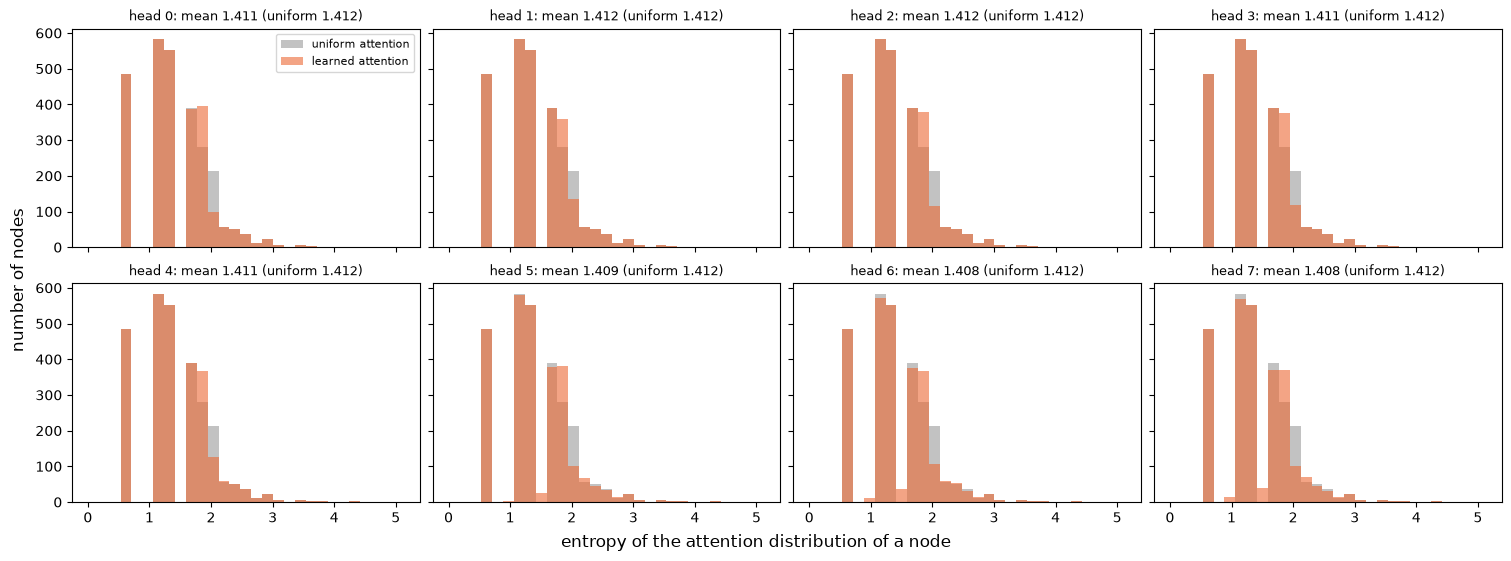

uniform weights        : 0.825 of the neighbour weight on same-class neighbours
GAT layer 1, head 0   : 0.825
GAT layer 1, head 1   : 0.825
GAT layer 1, head 2   : 0.825
GAT layer 1, head 3   : 0.825
GAT layer 1, head 4   : 0.825
GAT layer 1, head 5   : 0.826
GAT layer 1, head 6   : 0.826
GAT layer 1, head 7   : 0.826


In [16]:
gat.eval()
with torch.no_grad():
    gat(X, edge_index)
att_layer = gat.conv1
src_l, dst_l = att_layer.edge_index
alpha = att_layer.alpha                                                  # [E + N, 8]: first layer, every head
entropy = scatter_sum(-(alpha * alpha.clamp_min(1e-12).log()), dst_l, N)  # [N, 8]
uniform_entropy = degree(dst_l, N).log()                                 # log(d_i + 1)

fig, axes = plt.subplots(2, 4, figsize=(15, 5.5), sharex=True, sharey=True, constrained_layout=True)
bins = np.linspace(0, uniform_entropy.max().item(), 30)
for k, ax in enumerate(axes.flat):
    ax.hist(uniform_entropy.cpu(), bins=bins, color=COLORS['MLP'], alpha=0.6, label='uniform attention')
    ax.hist(entropy[:, k].cpu(), bins=bins, color=COLORS['GAT'], alpha=0.6, label='learned attention')
    ax.set_title(f'head {k}: mean {entropy[:, k].mean():.3f} (uniform {uniform_entropy.mean():.3f})', fontsize=9)
axes[0, 0].legend(fontsize=8)
fig.supxlabel('entropy of the attention distribution of a node')
fig.supylabel('number of nodes')
plt.show()

# Label agreement: attention mass on same-class neighbours (self-loop excluded) vs. the uniform share
nbr = src_l != dst_l
same = ((y[src_l] == y[dst_l]) & nbr).float()
has_nbr = degree(dst_l[nbr], N) > 0
uniform_share = scatter_sum(same, dst_l, N) / scatter_sum(nbr.float(), dst_l, N).clamp_min(1)
print(f'uniform weights        : {uniform_share[has_nbr].mean():.3f} of the neighbour weight on same-class neighbours')
for k in range(alpha.size(1)):
    share = scatter_sum(alpha[:, k] * same, dst_l, N) / scatter_sum(alpha[:, k] * nbr, dst_l, N).clamp_min(1e-12)
    print(f'GAT layer 1, head {k}   : {share[has_nbr].mean():.3f}')

On Cora, every head of the first layer is almost exactly uniform:
* The entropy of each head equals the entropy of uniform attention (1.41 vs. 1.41 on average).
* Each head gives same-class neighbours the same share of the weight as uniform weights do (0.825).

The inputs are sparse bag-of-words vectors, so the scores $e_{ij}$ hardly differ between the neighbours of a node. On this homophilous graph a plain average is already a good rule: 82.5% of the neighbour weight lands on same-class neighbours anyway. GAT therefore ends up very close to a GCN, and the two reach almost the same accuracy (83.1% vs. 82.7%).

# 3. GATv2: static vs. dynamic attention
## 3.1. GAT computes static attention

Write $C(i) = \mathbf a_1^\top W h_i$ and $K(j) = \mathbf a_2^\top W h_j$. Then GAT's score is

$$e(h_i, h_j) = \mathrm{LeakyReLU}\big(C(i) + K(j)\big).$$

LeakyReLU is strictly increasing and $C(i)$ is the same constant for all neighbours of $i$, so the ranking of the neighbours is the ranking of $K(j)$. That ranking is identical for every query node $i$; Brody et al. call this static attention. Check it on the trained GAT: for every node and head, is the neighbour with the largest $\alpha_{ij}$ the neighbour with the largest $K(j)$?

In [17]:
def top_edges(values, dst, N):
    """Boolean mask over the edges: True for the edge(s) with the largest value among the incoming edges of each node."""
    best = torch.full((N,), -float('inf'), device=values.device).scatter_reduce(0, dst, values, reduce='amax')
    return values == best[dst]

with torch.no_grad():
    z = att_layer.W(X).view(N, att_layer.heads, att_layer.out_dim)
    key_score = (z * att_layer.a_src).sum(-1)                      # K(j) = a_2ᵀ W h_j  [N, heads]

for k in range(att_layer.heads):
    top_alpha = top_edges(alpha[:, k], dst_l, N)                   # the most attended neighbour of each node
    top_key = top_edges(key_score[src_l, k], dst_l, N)             # the neighbour with the largest K(j)
    mismatch = scatter_sum((top_alpha != top_key).float(), dst_l, N) > 0
    print(f'head {k}: the most attended neighbour is the neighbour with the largest K(j) for '
          f'{(1 - mismatch.float().mean().item()) * 100:.1f}% of the nodes')

head 0: the most attended neighbour is the neighbour with the largest K(j) for 100.0% of the nodes
head 1: the most attended neighbour is the neighbour with the largest K(j) for 100.0% of the nodes
head 2: the most attended neighbour is the neighbour with the largest K(j) for 100.0% of the nodes
head 3: the most attended neighbour is the neighbour with the largest K(j) for 100.0% of the nodes
head 4: the most attended neighbour is the neighbour with the largest K(j) for 100.0% of the nodes
head 5: the most attended neighbour is the neighbour with the largest K(j) for 100.0% of the nodes
head 6: the most attended neighbour is the neighbour with the largest K(j) for 100.0% of the nodes
head 7: the most attended neighbour is the neighbour with the largest K(j) for 100.0% of the nodes


## 3.2. GATv2 layer

GATv2 swaps the order of the non-linearity and the projection $\mathbf a$:

$$e(h_i, h_j) = \mathbf a^\top \mathrm{LeakyReLU}\big(W [h_i\,\|\,h_j]\big) = \mathbf a^\top\mathrm{LeakyReLU}\big(W_t h_i + W_s h_j\big),\qquad W = [W_t\,|\,W_s].$$

The score is now a one-hidden-layer MLP of the pair (input $[h_i\|h_j]$, hidden layer $W$ + LeakyReLU, output $\mathbf a^\top$): a universal approximator, so the ranking of the keys can depend on the query (dynamic attention). As in PyG's `GATv2Conv`, the message is $W_s h_j$ (PyG names $W_s$ `lin_l` and $W_t$ `lin_r`).

In [18]:
from torch_geometric.nn import GATv2Conv

class GATv2Layer(nn.Module):
    """GATv2 layer (Brody et al., ICLR 2022) with K heads on the edge list:
         e_ij = aᵀ LeakyReLU(W_t h_i + W_s h_j),   α_ij = softmax_j(e_ij),   h_i' = Σ_j α_ij W_s h_j"""
    def __init__(self, in_dim, out_dim, heads=1, concat=True, dropout=0.6, negative_slope=0.2, self_loops=True,
                 share_weights=False):
        super().__init__()
        self.heads, self.out_dim, self.concat = heads, out_dim, concat
        self.dropout, self.negative_slope, self.self_loops = dropout, negative_slope, self_loops
        self.W_s = nn.Linear(in_dim, heads * out_dim)                     # source part of W (= PyG lin_l)
        self.W_t = self.W_s if share_weights else nn.Linear(in_dim, heads * out_dim)   # target part (= lin_r)
        self.a = nn.Parameter(torch.empty(heads, out_dim))
        self.bias = nn.Parameter(torch.zeros(heads * out_dim if concat else out_dim))
        for lin in [self.W_s] if share_weights else [self.W_s, self.W_t]:
            glorot_(lin.weight); nn.init.zeros_(lin.bias)
        glorot_(self.a)

    def forward(self, x, edge_index):
        N = x.size(0)
        if self.self_loops:
            edge_index = add_self_loops(edge_index, N)
        src, dst = edge_index
        zs = self.W_s(x).view(N, self.heads, self.out_dim)
        zt = self.W_t(x).view(N, self.heads, self.out_dim)
        # ★ KEY: LeakyReLU acts on the joint vector BEFORE the projection a, so i and j interact (dynamic attention).
        e = (F.leaky_relu(zt[dst] + zs[src], self.negative_slope) * self.a).sum(-1)
        alpha = edge_softmax(e, dst, N)
        self.edge_index, self.alpha = edge_index, alpha.detach()
        alpha = F.dropout(alpha, self.dropout, self.training)
        out = scatter_sum(alpha.unsqueeze(-1) * zs[src], dst, N)
        out = out.reshape(N, -1) if self.concat else out.mean(dim=1)
        return out + self.bias

    def extra_repr(self):
        return f'heads={self.heads}, concat={self.concat}'

for heads, concat in [(8, True), (3, False)]:
    ours = GATv2Layer(num_features, 8, heads=heads, concat=concat, dropout=0.0).to(device)
    pyg = GATv2Conv(num_features, 8, heads=heads, concat=concat, dropout=0.0).to(device)
    with torch.no_grad():
        pyg.lin_l.weight.copy_(ours.W_s.weight); pyg.lin_l.bias.copy_(ours.W_s.bias)
        pyg.lin_r.weight.copy_(ours.W_t.weight); pyg.lin_r.bias.copy_(ours.W_t.bias)
        pyg.att.copy_(ours.a.view(1, heads, 8)); pyg.bias.copy_(ours.bias)
    diff = (ours(X, edge_index) - pyg(X, edge_index)).abs().max().item()
    print(f'GATv2Layer vs. GATv2Conv (heads={heads}, concat={concat}) | max |difference| = {diff:.1e}')

GATv2Layer vs. GATv2Conv (heads=8, concat=True) | max |difference| = 4.7e-09
GATv2Layer vs. GATv2Conv (heads=3, concat=False) | max |difference| = 1.9e-09


## 3.3. DictionaryLookup: a task that needs dynamic attention (GATv2)

Brody et al.'s benchmark: every graph has $k=10$ key nodes $k_0,\dots,k_9$ and $k$ query nodes $q_0,\dots,q_9$, and every key sends an edge to every query (complete bipartite graph).
* key $k_j$: features $[\text{one-hot}(j)\,\|\,\text{one-hot}(v_j)]$ with a random value $v_j\in\{0,\dots,k-1\}$,
* query $q_i$: features $[\text{one-hot}(i)\,\|\,\mathbf 0]$, label $v_i$ (the value of the key with the same id).

Each query must put its attention on a different key, which static attention cannot do. Model: one attention layer (1 head, no self-loops) and a linear classifier.

In [19]:
def make_lookup_graphs(num_graphs, k, seed):
    """Disjoint DictionaryLookup graphs. In every graph, nodes 0..k-1 are the keys and k..2k-1 the queries.
    Keys get the label -1 (they are not classified)."""
    g = torch.Generator().manual_seed(seed)
    ids = torch.eye(k)
    xs, edges, labels = [], [], []
    for b in range(num_graphs):
        values = torch.randint(0, k, (k,), generator=g)
        keys = torch.cat([ids, F.one_hot(values, k).float()], dim=1)
        queries = torch.cat([ids, torch.zeros(k, k)], dim=1)
        offset = 2 * k * b
        src = torch.arange(k).repeat_interleave(k) + offset         # every key j ...
        dst = torch.arange(k, 2 * k).repeat(k) + offset             # ... sends an edge to every query i
        xs.append(torch.cat([keys, queries]))
        edges.append(torch.stack([src, dst]))
        labels.append(torch.cat([torch.full((k,), -1), values]))
    return torch.cat(xs).to(device), torch.cat(edges, dim=1).to(device), torch.cat(labels).to(device)

class LookupNet(nn.Module):
    """One attention layer (no self-loops: a query must read its answer from a key) + a linear classifier."""
    def __init__(self, k, layer, heads=1, hidden=64):
        super().__init__()
        self.conv = layer(2 * k, hidden, heads=heads, concat=False, dropout=0.0, self_loops=False)
        self.out = nn.Linear(hidden, k)

    def forward(self, x, edge_index):
        return self.out(F.relu(self.conv(x, edge_index)))

def train_lookup(model, train_graphs, test_graphs, epochs=500, lr=0.005):
    """Full-batch training on the queries of all training graphs; returns (train accuracy, test accuracy)."""
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    x, ei, labels = train_graphs
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        F.cross_entropy(model(x, ei)[labels >= 0], labels[labels >= 0]).backward()
        optimizer.step()
    model.eval()
    with torch.no_grad():
        return tuple(accuracy(model(xx, ee).argmax(1)[ll >= 0], ll[ll >= 0]) for xx, ee, ll in (train_graphs, test_graphs))

In [20]:
k = 10
train_graphs, test_graphs = make_lookup_graphs(1000, k, seed=0), make_lookup_graphs(200, k, seed=1)
lookup_models = {}
for name, layer in [('GAT', GATLayer), ('GATv2', GATv2Layer)]:
    set_seed(0)
    lookup_models[name] = LookupNet(k, layer)
    train_acc, test_acc = train_lookup(lookup_models[name], train_graphs, test_graphs)
    print(f'{name:<6} | train acc {train_acc*100:5.1f}% | test acc {test_acc*100:5.1f}%   (chance: {100 / k:.0f}%)')

GAT    | train acc  29.7% | test acc  30.0%   (chance: 10%)
GATv2  | train acc 100.0% | test acc 100.0%   (chance: 10%)


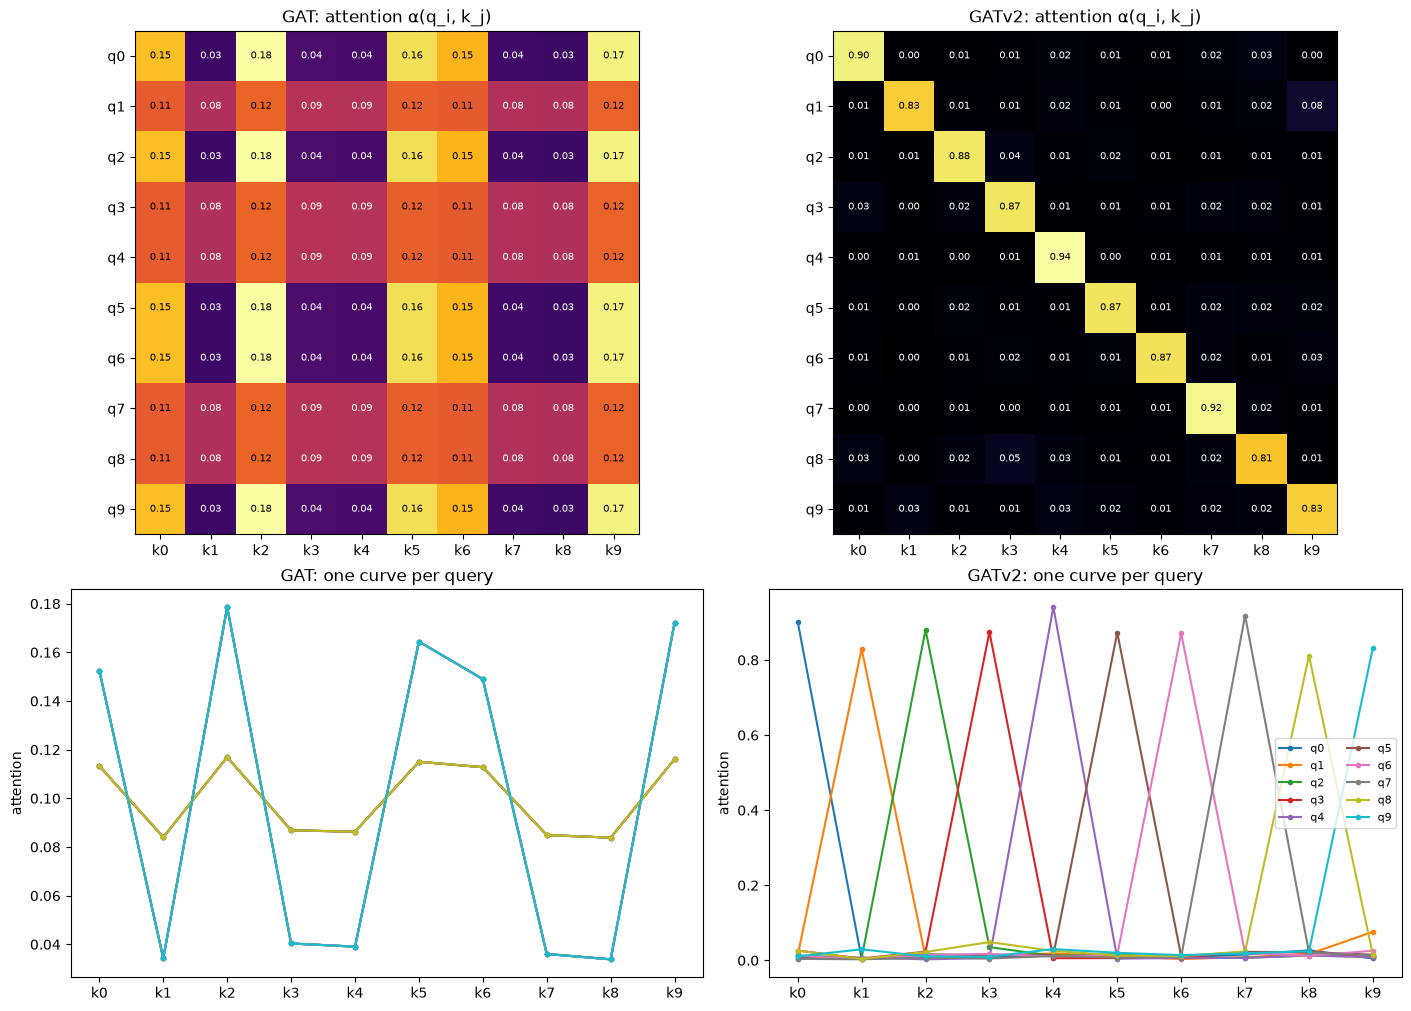

In [21]:
# Attention of every query on every key for the first test graph
x_one, ei_one, _ = make_lookup_graphs(1, k, seed=1)          # = the first graph of test_graphs
fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True, gridspec_kw={'height_ratios': [1.3, 1]})
for col, (name, model) in enumerate(lookup_models.items()):
    with torch.no_grad():
        model(x_one, ei_one)
    s, d = model.conv.edge_index
    att = torch.zeros(k, k)
    att[(d - k).cpu(), s.cpu()] = model.conv.alpha[:, 0].cpu()       # att[query i, key j]
    ax = axes[0, col]
    ax.imshow(att, cmap='inferno', vmin=0, vmax=att.max().item())
    for i in range(k):
        for j in range(k):
            ax.text(j, i, f'{att[i, j]:.2f}', ha='center', va='center', fontsize=7,
                    color='black' if att[i, j] > 0.6 * att.max() else 'white')
    ax.set(xticks=range(k), xticklabels=[f'k{j}' for j in range(k)], yticks=range(k),
           yticklabels=[f'q{i}' for i in range(k)], title=f'{name}: attention α(q_i, k_j)')
    for i in range(k):
        axes[1, col].plot(range(k), att[i], marker='.', label=f'q{i}')
    axes[1, col].set(xticks=range(k), xticklabels=[f'k{j}' for j in range(k)], ylabel='attention',
                     title=f'{name}: one curve per query')
axes[1, 1].legend(ncol=2, fontsize=8)
plt.show()

GAT is stuck at 30%, while GATv2 solves the task (100% on the training and the test graphs). The heatmaps show why:
* GAT: every row ranks the keys in the same order ($k_2$, $k_9$, $k_5$, $k_0$, $k_6$ are always on top), which gives the vertical bands. The query only changes how sharp the distribution is: the rows fall into two groups (two families of curves), but the ranking never changes. A query cannot single out its own key, so it reads a blurred mixture of all values.
* GATv2: each query puts 81–94% of its attention on the key with the same id, which gives the diagonal.

## 3.4. GATv2 on Cora

Same architecture and hyper-parameters as the GAT, with the GATv2 layer.

In [22]:
benchmark('GATv2', lambda: GAT(num_features, 8, num_classes, layer=GATv2Layer))

GATv2                  | Test Acc: 82.87 ± 0.33


On Cora, GATv2 (82.8 ± 0.4%) and GAT (83.1 ± 0.7%) are within one standard deviation of each other. Classifying papers does not need a query-dependent ranking of the neighbours, since the attention is close to uniform anyway. Dynamic attention pays off when which neighbour matters depends on who is asking, as in DictionaryLookup.

# 4. SuperGAT: self-supervised graph attention
## 4.1. Four attention forms and the self-supervised edge loss

GAT's attention is trained only through the node classification loss, so nothing tells it that an edge exists for a reason. SuperGAT (Kim & Oh, ICLR 2021) asks the unnormalised attention to also predict whether $j\to i$ is an edge: $\phi_{ij} = \sigma(\cdot)$ is an edge probability.

| Form | attention logit $e_{ij}$ | edge logit ($\phi_{ij}=\sigma(\cdot)$) |
|:--|:--|:--|
| GO: (original GAT) | $\mathbf a^\top[Wh_i\,\Vert\,Wh_j]$ | $e^{GO}_{ij}$ |
| DP: (dot product) | $(Wh_i)^\top(Wh_j)$ | $e^{DP}_{ij}$ |
| SD: (scaled dot product) | $(Wh_i)^\top(Wh_j)/\sqrt{F'}$ | $e^{SD}_{ij}$ |
| MX: (mixed) | $e^{GO}_{ij}\cdot\sigma(e^{DP}_{ij})$ | $e^{DP}_{ij}$ |

In every form, $\alpha_{ij}=\mathrm{softmax}_j(\mathrm{LeakyReLU}(e_{ij}))$. The self-supervised loss is a binary cross-entropy over a sample of the edges $\mathcal E$ and of random non-edges $\mathcal E^-$ (negative sampling):

$$\mathcal L_{SS} = -\frac{1}{|\mathcal E|}\sum_{(i,j)\in\mathcal E}\log\phi_{ij} - \frac{1}{|\mathcal E^-|}\sum_{(i,j)\in\mathcal E^-}\log(1-\phi_{ij}),\qquad
\mathcal L = \mathcal L_{NC} + \lambda_E\sum_{\text{layers}}\mathcal L_{SS} + \lambda_{reg}\|\Theta\|_2^2 .$$

As in PyG's SuperGAT example, every training epoch samples 80% of the edges as positives and half as many random non-edges as negatives, $\lambda_E = 4$, and the output layer averages 8 heads. With $\lambda_E = 0$, SuperGAT-GO is exactly a GAT with 8 output heads.

In [23]:
def negative_sampling(edge_index, N, num):
    """`num` uniformly random node pairs (i, j), i != j, that are not edges of the graph."""
    existing = edge_index[0] * N + edge_index[1]
    out = torch.empty(0, dtype=torch.long, device=edge_index.device)
    while out.numel() < num:
        cand = torch.randint(0, N * N, (int(1.2 * num) + 10,), device=edge_index.device)
        cand = cand[(cand // N != cand % N) & ~torch.isin(cand, existing)]
        out = torch.cat([out, cand])
    out = out[:num]
    return torch.stack([out // N, out % N])

class SuperGATLayer(nn.Module):
    """SuperGAT layer with attention form 'GO', 'DP', 'SD' or 'MX'."""
    def __init__(self, in_dim, out_dim, heads=1, concat=True, dropout=0.6, attention_type='MX',
                 edge_ratio=0.8, neg_ratio=0.5, negative_slope=0.2):
        super().__init__()
        self.heads, self.out_dim, self.concat, self.dropout = heads, out_dim, concat, dropout
        self.type, self.edge_ratio, self.neg_ratio, self.negative_slope = attention_type, edge_ratio, neg_ratio, negative_slope
        self.W = nn.Linear(in_dim, heads * out_dim, bias=False)
        glorot_(self.W.weight)
        if attention_type in ('GO', 'MX'):
            self.a_dst = nn.Parameter(glorot_(torch.empty(heads, out_dim)))
            self.a_src = nn.Parameter(glorot_(torch.empty(heads, out_dim)))
        self.bias = nn.Parameter(torch.zeros(heads * out_dim if concat else out_dim))
        self.ss_loss = torch.tensor(0.)

    def scores(self, z, src, dst):
        """Returns (attention logit e_ij, edge logit), both [E, heads], for the edges src -> dst."""
        if self.type in ('GO', 'MX'):
            go = (z[dst] * self.a_dst).sum(-1) + (z[src] * self.a_src).sum(-1)
            if self.type == 'GO':
                return go, go
        dp = (z[dst] * z[src]).sum(-1)
        if self.type == 'DP':
            return dp, dp
        if self.type == 'SD':
            return dp / math.sqrt(self.out_dim), dp / math.sqrt(self.out_dim)
        # ★ KEY: MX aggregates with GO attention gated by σ(DP), but predicts edges with DP alone.
        return go * torch.sigmoid(dp), dp

    def forward(self, x, edge_index):
        N = x.size(0)
        ei = add_self_loops(edge_index, N)
        src, dst = ei
        z = self.W(x).view(N, self.heads, self.out_dim)
        e, _ = self.scores(z, src, dst)
        alpha = edge_softmax(F.leaky_relu(e, self.negative_slope), dst, N)
        self.edge_index, self.alpha, self.z = ei, alpha.detach(), z.detach()
        if self.training:
            # ★ KEY: Self-supervision: the edge logits must separate real edges from random non-edges.
            E = edge_index.size(1)
            pos = edge_index[:, torch.randperm(E, device=x.device)[:int(self.edge_ratio * E)]]
            neg = negative_sampling(edge_index, N, int(self.neg_ratio * pos.size(1)))
            logits = torch.cat([self.scores(z, pos[0], pos[1])[1], self.scores(z, neg[0], neg[1])[1]]).mean(-1)
            labels = torch.cat([torch.ones(pos.size(1)), torch.zeros(neg.size(1))]).to(x.device)
            self.ss_loss = F.binary_cross_entropy_with_logits(logits, labels)
        alpha = F.dropout(alpha, self.dropout, self.training)
        out = scatter_sum(alpha.unsqueeze(-1) * z[src], dst, N)
        out = out.reshape(N, -1) if self.concat else out.mean(dim=1)
        return out + self.bias

    def edge_logit(self, pairs):
        """Edge logit of node pairs (row 0 = j, row 1 = i), averaged over the heads (call after a forward pass)."""
        return self.scores(self.z, pairs[0], pairs[1])[1].mean(-1)

class SuperGAT(nn.Module):
    """2-layer SuperGAT (same shape as GAT); aux_loss() = λ_E · (L_SS of layer 1 + L_SS of layer 2)."""
    def __init__(self, in_dim, hidden_dim, out_dim, heads=8, out_heads=8, attention_type='MX', lambda_e=4.0,
                 dropout=0.6):
        super().__init__()
        self.conv1 = SuperGATLayer(in_dim, hidden_dim, heads, True, dropout, attention_type)
        self.conv2 = SuperGATLayer(hidden_dim * heads, out_dim, out_heads, False, dropout, attention_type)
        self.dropout, self.lambda_e = dropout, lambda_e

    def forward(self, x, edge_index):
        x = F.dropout(x, self.dropout, self.training)
        x = F.elu(self.conv1(x, edge_index))
        x = F.dropout(x, self.dropout, self.training)
        return self.conv2(x, edge_index)

    def aux_loss(self):
        return self.lambda_e * (self.conv1.ss_loss + self.conv2.ss_loss)

In [24]:
benchmark('GAT (8 output heads)', lambda: SuperGAT(num_features, 8, num_classes, attention_type='GO', lambda_e=0.0))
for att_type in ['GO', 'DP', 'SD', 'MX']:
    benchmark(f'SuperGAT-{att_type}', lambda: SuperGAT(num_features, 8, num_classes, attention_type=att_type))

GAT (8 output heads)   | Test Acc: 82.30 ± 0.24
SuperGAT-GO            | Test Acc: 82.43 ± 0.21
SuperGAT-DP            | Test Acc: 82.70 ± 0.28
SuperGAT-SD            | Test Acc: 82.60 ± 0.36
SuperGAT-MX            | Test Acc: 83.67 ± 0.40


With the same architecture, the self-supervised edge loss improves the plain GAT (82.3%) for GO, DP and MX. MX (83.6%) and DP (82.7%) are the best, while SD is not better here. The differences are only 1–2 points. Cora is homophilous (0.81) but sparse (mean degree 3.9), recommends MX or GO.

## 4.2. What does the attention learn?

Two measurements from the SuperGAT paper:
* Link prediction: hide 10% of the edges, train on the remaining graph, and compute the AUC of the edge logit on the hidden edges against as many random non-edges. AUC 0.5 means the attention knows nothing about the graph structure.
* Label agreement: for node $i$, the label-agreement distribution is $\ell_{ij}\propto\mathbb 1[y_i=y_j]$ over its neighbourhood (self-loop included). Report the mean of $\mathrm{KL}(\ell_i\,\|\,\alpha_i)$ over the nodes; lower means the attention follows the labels.

In [25]:
def split_edges(edge_index, test_ratio=0.1, seed=0):
    """Hide a fraction of the undirected edges (both directions); returns (training edges, hidden edges i < j)."""
    g = torch.Generator().manual_seed(seed)
    und = edge_index[:, edge_index[0] < edge_index[1]]
    perm = torch.randperm(und.size(1), generator=g).to(edge_index.device)
    n_test = int(test_ratio * und.size(1))
    test, train = und[:, perm[:n_test]], und[:, perm[n_test:]]
    return torch.cat([train, train.flip(0)], dim=1), test

def auc(pos, neg):
    """Area under the ROC curve = P(score of a random positive > score of a random negative)."""
    scores = torch.cat([pos, neg])
    ranks = torch.empty_like(scores)
    ranks[scores.argsort()] = torch.arange(1, scores.numel() + 1, device=scores.device, dtype=scores.dtype)
    return ((ranks[:pos.numel()].sum() - pos.numel() * (pos.numel() + 1) / 2) / (pos.numel() * neg.numel())).item()

def kl_label_agreement(layer, labels):
    """Mean over the nodes of KL(ℓ_i || α_i), ℓ_ij ∝ 1[y_i = y_j] over the neighbourhood, α averaged over the heads."""
    s, d = layer.edge_index
    n = labels.size(0)
    att = layer.alpha.mean(-1)
    same = (labels[s] == labels[d]).float()
    l = same / scatter_sum(same, d, n)[d]
    kl = torch.where(l > 0, l * (l.clamp_min(1e-12).log() - att.clamp_min(1e-12).log()), torch.zeros_like(l))
    return scatter_sum(kl, d, n).mean().item()

train_edges, hidden_edges = split_edges(edge_index)
hidden_neg = negative_sampling(edge_index, N, hidden_edges.size(1))
print(f'training edges: {train_edges.size(1) // 2} | hidden edges: {hidden_edges.size(1)} | random non-edges: {hidden_neg.size(1)}')

print(f"{'model':<22}{'test acc':>9}{'AUC L1':>8}{'AUC L2':>8}{'KL L1':>8}{'KL L2':>8}")
for att_type, lam in [('GO', 0.0), ('GO', 4.0), ('DP', 0.0), ('DP', 4.0), ('SD', 4.0), ('MX', 4.0)]:
    set_seed(0)
    model = SuperGAT(num_features, 8, num_classes, attention_type=att_type, lambda_e=lam)
    _, acc = train_model(model, (X, train_edges))
    model.eval()
    with torch.no_grad():
        model(X, train_edges)
        aucs = [auc(layer.edge_logit(hidden_edges), layer.edge_logit(hidden_neg)) for layer in (model.conv1, model.conv2)]
        kls = [kl_label_agreement(layer, y) for layer in (model.conv1, model.conv2)]
    print(f'{att_type + ", λ_E = " + str(lam):<22}{acc*100:>8.1f}%{aucs[0]:>8.3f}{aucs[1]:>8.3f}{kls[0]:>8.3f}{kls[1]:>8.3f}')

training edges: 4751 | hidden edges: 527 | random non-edges: 527
model                  test acc  AUC L1  AUC L2   KL L1   KL L2
GO, λ_E = 0.0             82.1%   0.507   0.511   0.177   0.180
GO, λ_E = 4.0             81.4%   0.607   0.560   0.192   0.180
DP, λ_E = 0.0             81.2%   0.794   0.829   0.175   0.675
DP, λ_E = 4.0             82.7%   0.844   0.880   0.175   0.235
SD, λ_E = 4.0             81.1%   0.829   0.862   0.175   0.221
MX, λ_E = 4.0             82.8%   0.849   0.885   0.176   0.181


* Link prediction. GO's logits know almost nothing about the graph: AUC 0.507–0.511 is chance level. Even when they are trained to predict edges ($\lambda_E=4$), they only reach 0.56–0.60. This is the failure in structural encoding. The dot-product forms predict the hidden edges well: DP already reaches 0.79 without self-supervision, and DP / SD / MX with self-supervision reach 0.84–0.88. DP is a graph autoencoder.
* Label agreement. In the first layer every form is close to uniform (KL 0.175–0.19). In the second layer, DP without self-supervision follows the labels badly (KL 0.54). DP and SD with self-supervision (0.24 and 0.22) are still worse than GO (0.18–0.19): the dot product rewards neighbours with similar hidden vectors, which is not the same as neighbours with the same label.
* MX gets both. The edge loss acts on the DP logits (AUC 0.86 / 0.88), while the aggregation uses GO attention gated by $\sigma(e^{DP})$ (KL 0.185, as good as GO). This is the decoupling.

# 5. Theory of attention on the CSBM
## 5.1. The contextual stochastic block model 

A CSBM couples a Gaussian mixture (node features) with a stochastic block model (edges). The $n$ nodes form two balanced classes $\mathcal C_0, \mathcal C_1$:

$$X_i\sim\mathcal N(\mu,\sigma^2 I_d)\ \text{if } i\in\mathcal C_0,\qquad X_i\sim\mathcal N(-\mu,\sigma^2 I_d)\ \text{if } i\in\mathcal C_1,\qquad
\mathbb P(A_{ij}=1)=\begin{cases}p & \text{same class}\\ q & \text{different classes}\end{cases}$$

$\|\mu\|/\sigma$ controls the feature noise and the gap $|p-q|$ the structure noise. With $q = p$ the graph says nothing about the classes.

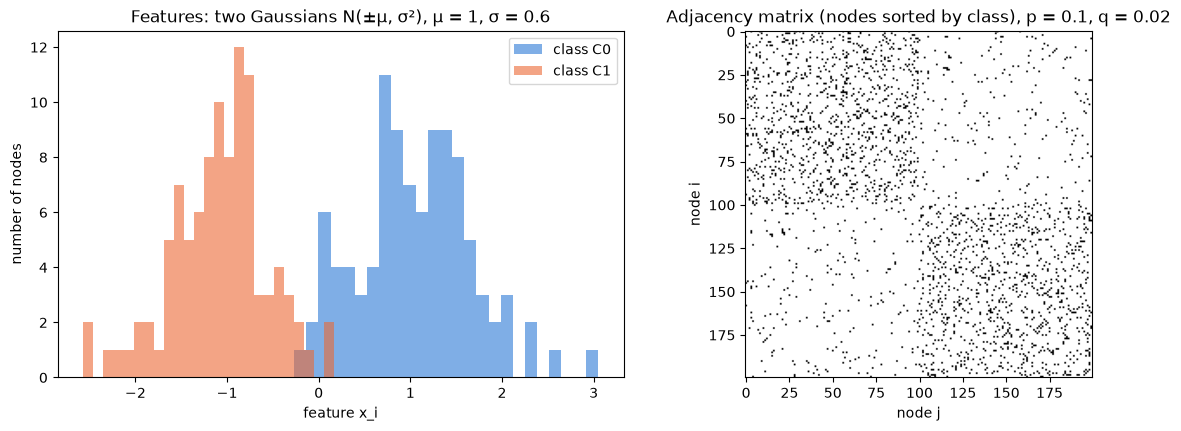

In [26]:
def csbm(n, p, q, mu, sigma=1.0, d=1, seed=0):
    """Two-class CSBM: X_i ~ N(±μ, σ² I_d) with μ = (mu, 0, ..., 0); edges with probability p (same class) or q.
    Returns features [n, d], labels (C0 -> 0, C1 -> 1) and an undirected edge_index without self-loops."""
    g = torch.Generator().manual_seed(seed)
    labels = torch.cat([torch.zeros(n // 2), torch.ones(n - n // 2)]).long()
    sign = 1 - 2 * labels.float()                                   # +1 for C0, -1 for C1
    X = sigma * torch.randn(n, d, generator=g)
    X[:, 0] += sign * mu
    P = torch.where(labels[:, None] == labels[None, :], torch.tensor(p), torch.tensor(q))
    A = torch.triu((torch.rand(n, n, generator=g) < P).float(), diagonal=1)
    edge_index = (A + A.t()).nonzero().t()
    return X.to(device), labels.to(device), edge_index.to(device)

Xc, yc, eic = csbm(200, p=0.1, q=0.02, mu=1.0, sigma=0.6, seed=0)
A_c = torch.zeros(200, 200)
A_c[eic[0].cpu(), eic[1].cpu()] = 1
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
for c, color in [(0, COLORS['GCN']), (1, COLORS['GAT'])]:
    ax[0].hist(Xc[yc == c, 0].cpu(), bins=25, alpha=0.6, color=color, label=f'class C{c}')
ax[0].set(xlabel='feature x_i', ylabel='number of nodes', title='Features: two Gaussians N(±μ, σ²), μ = 1, σ = 0.6')
ax[0].legend()
ax[1].imshow(A_c, cmap='Greys')
ax[1].set(title='Adjacency matrix (nodes sorted by class), p = 0.1, q = 0.02', xlabel='node j', ylabel='node i')
plt.show()

## 5.2. Easy vs. hard regime (Fountoulakis et al.)

* Easy regime, $\|\mu\| = \omega(\sigma\sqrt{\log n})$: an attention function (a 2-layer MLP) separates the intra-class from the inter-class edges, so the attention concentrates on the intra-class edges.
* Hard regime, $\|\mu\| = \kappa\sigma$ with $\kappa = O(1)$: no attention function separates the edges. GAT's coefficients become almost uniform and GAT behaves like a GCN. It still stays at least as good as a linear classifier on the features, because it can weight the self-loop.

Setup: $n=1000$, $p=0.5$, $d=2$, and $q$ goes from 0 to 1. One aggregation layer and a linear classifier are trained on half of the nodes and tested on the other half, for four models:
* no graph: a linear classifier on the features,
* GCN: uniform weights over $\mathcal N(i)\cup\{i\}$,
* GAT and GATv2: GATv2's score is exactly a one-hidden-layer MLP of the pair (the MLP attention of the theory).

The easy regime uses $\|\mu\|/\sigma = 2\sqrt{2\log n}\approx 7.4$ and the hard regime $\|\mu\|/\sigma = 0.5$.

easy regime (||μ||/σ = 7.43) | accuracy at q = p: no graph 1.000, GCN 0.552, GAT 1.000, GATv2 1.000
hard regime (||μ||/σ = 0.50) | accuracy at q = p: no graph 0.682, GCN 0.514, GAT 0.700, GATv2 0.636


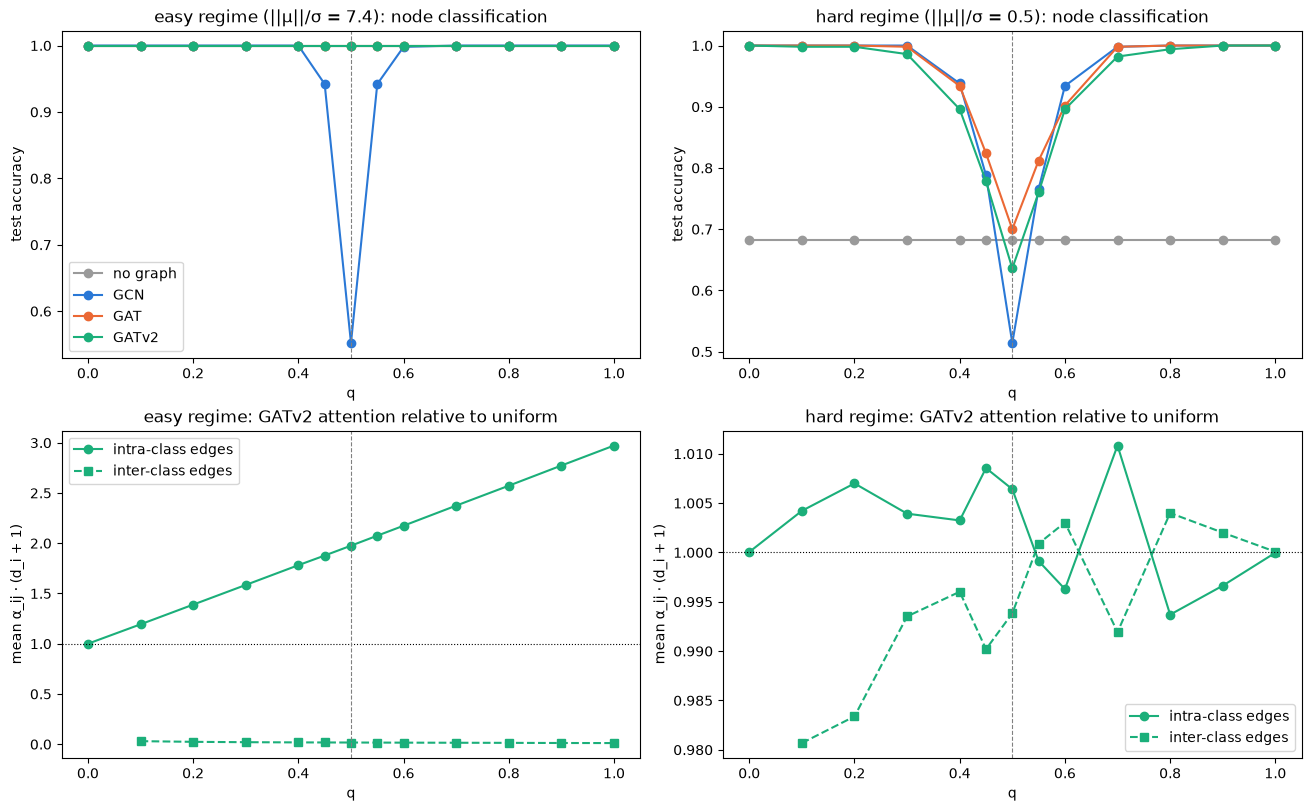

In [27]:
class OneLayerNet(nn.Module):
    """One aggregation layer (16 features) + a linear classifier. kind: 'no graph', 'GCN' (uniform weights over
    N(i) ∪ {i}), 'GAT' or 'GATv2' (learned attention over N(i) ∪ {i})."""
    def __init__(self, in_dim, kind, hidden=16):
        super().__init__()
        self.kind = kind
        if kind == 'GAT':
            self.conv = GATLayer(in_dim, hidden, dropout=0.0)
        elif kind == 'GATv2':
            self.conv = GATv2Layer(in_dim, hidden, dropout=0.0)
        else:
            self.conv = nn.Linear(in_dim, hidden)
        self.out = nn.Linear(hidden, 2)

    def forward(self, x, edge_index):
        if self.kind == 'no graph':
            h = self.conv(x)
        elif self.kind == 'GCN':                      # uniform attention: the mean over N(i) ∪ {i}
            n = x.size(0)
            s, d = add_self_loops(edge_index, n)
            h = scatter_sum(self.conv(x)[s], d, n) / degree(d, n)[:, None]
        else:
            h = self.conv(x, edge_index)
        return self.out(h)

def fit_and_test(model, x, edge_index, labels, train_idx, test_idx, epochs=300, lr=0.01):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        model.train()
        optimizer.zero_grad()
        F.cross_entropy(model(x, edge_index)[train_idx], labels[train_idx]).backward()
        optimizer.step()
    model.eval()
    with torch.no_grad():
        return accuracy(model(x, edge_index).argmax(1)[test_idx], labels[test_idx])

n_c, p_c, d_c = 1000, 0.5, 2
regimes = {'easy': 2 * math.sqrt(2 * math.log(n_c)), 'hard': 0.5}          # ||μ|| / σ
qs = [0.0, 0.1, 0.2, 0.3, 0.4, 0.45, 0.5, 0.55, 0.6, 0.7, 0.8, 0.9, 1.0]
kinds = ['no graph', 'GCN', 'GAT', 'GATv2']
perm = torch.randperm(n_c, generator=torch.Generator().manual_seed(0)).to(device)
train_idx, test_idx = perm[:n_c // 2], perm[n_c // 2:]
csbm_acc = {r: {kind: [] for kind in kinds} for r in regimes}
csbm_att = {r: {'intra-class edges': [], 'inter-class edges': []} for r in regimes}
for regime, mu in regimes.items():
    for q in qs:
        Xc, yc, eic = csbm(n_c, p_c, q, mu, d=d_c, seed=0)
        for kind in kinds:
            set_seed(0)
            model = OneLayerNet(d_c, kind)
            csbm_acc[regime][kind].append(fit_and_test(model, Xc, eic, yc, train_idx, test_idx))
        # GATv2 (last model): attention relative to uniform attention, α_ij · (d_i + 1); 1 = uniform
        s, dd = model.conv.edge_index
        rel = model.conv.alpha[:, 0] * degree(dd, n_c)[dd]
        for name, mask in [('intra-class edges', (yc[s] == yc[dd]) & (s != dd)), ('inter-class edges', yc[s] != yc[dd])]:
            csbm_att[regime][name].append(rel[mask].mean().item() if mask.any() else float('nan'))
    print(f'{regime} regime (||μ||/σ = {mu:.2f}) | accuracy at q = p: ' +
          ', '.join(f'{kind} {csbm_acc[regime][kind][qs.index(p_c)]:.3f}' for kind in kinds))

fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
kind_colors = {'no graph': COLORS['MLP'], 'GCN': COLORS['GCN'], 'GAT': COLORS['GAT'], 'GATv2': COLORS['GATv2']}
for col, (regime, mu) in enumerate(regimes.items()):
    for kind in kinds:
        axes[0, col].plot(qs, csbm_acc[regime][kind], 'o-', color=kind_colors[kind], label=kind)
    axes[0, col].set(title=f'{regime} regime (||μ||/σ = {mu:.1f}): node classification', xlabel='q', ylabel='test accuracy')
    for name, style in [('intra-class edges', 'o-'), ('inter-class edges', 's--')]:
        axes[1, col].plot(qs, csbm_att[regime][name], style, color=COLORS['GATv2'], label=name)
    axes[1, col].axhline(1, color='black', lw=0.8, ls=':')
    axes[1, col].set(title=f'{regime} regime: GATv2 attention relative to uniform', xlabel='q', ylabel='mean α_ij · (d_i + 1)')
    for ax in axes[:, col]:
        ax.axvline(p_c, color='grey', lw=0.8, ls='--')
    axes[1, col].legend()
axes[0, 0].legend()
plt.show()

* Easy regime (left).
  * GAT and GATv2 are perfect for every $q$. GCN drops to 55% at $q=p$, where averaging over a random neighbourhood washes out the features.
  * GATv2 gives intra-class edges 1.2 to 3 times the uniform weight and inter-class edges almost nothing (≈ 0.02 of it). The edges are separated, and the attention concentrates on the important ones.
* Hard regime (right).
  * The attention stays within about 2% of uniform for every $q$.
  * GAT and GATv2 therefore follow the GCN curve: perfect when the graph alone reveals the classes ($q$ far from $p$), worst at $q=p$.
* Robustness, at $q=p$ in the hard regime:
  * GCN falls to 51%, while GAT keeps the accuracy of the linear classifier on the features (69.6% vs. 68.2%). It does not need sharp attention for this: since $\mathrm{LeakyReLU}(C(i)+K(j))$ depends on the node's own $C(i)$, the weights still carry information about the node itself.
  * One-layer GATv2 (62%) falls between GCN and the linear classifier. The theorem says that some attention function is robust, not that training finds it.

## 5.3. Graph attention is not always beneficial (Ma et al.)

Ma et al. analyse a parameter-free attention with an intensity $t$: $\alpha_{ij}\propto\exp(t\cdot\mathrm{sim}(x_i,x_j))$ over the neighbours of $i$, on 1-D features. Use $\mathrm{sim}(x_i,x_j)=\mathrm{sign}(x_i)\,\mathrm{sign}(x_j)$, i.e. $+1$ when the two features have the same sign and $-1$ otherwise. $t=0$ is mean aggregation (a GCN); a large $t$ keeps almost only the neighbours whose feature has the same sign.

Take a node of $\mathcal C_0$ when all signs are correct. It has about $pn/2$ same-class neighbours with weight $e^{t}$ and $qn/2$ other-class neighbours with weight $e^{-t}$, so the class mean shrinks by

$$\frac{p e^{t} - q e^{-t}}{p e^{t} + q e^{-t}} = 1-\frac{2q}{p e^{2t}+q}\quad\text{per layer}\qquad\Rightarrow\qquad \gamma(X^{(l)}) = \Big(1-\frac{2q}{p e^{2t}+q}\Big)^{l}\gamma(X^{(0)}),$$

where $\gamma$ is half the distance between the two class means. At $t=0$ this is the GCN rate $\frac{p-q}{p+q}$: the distance decays exponentially (over-smoothing). A large $t$ keeps the factor close to 1.

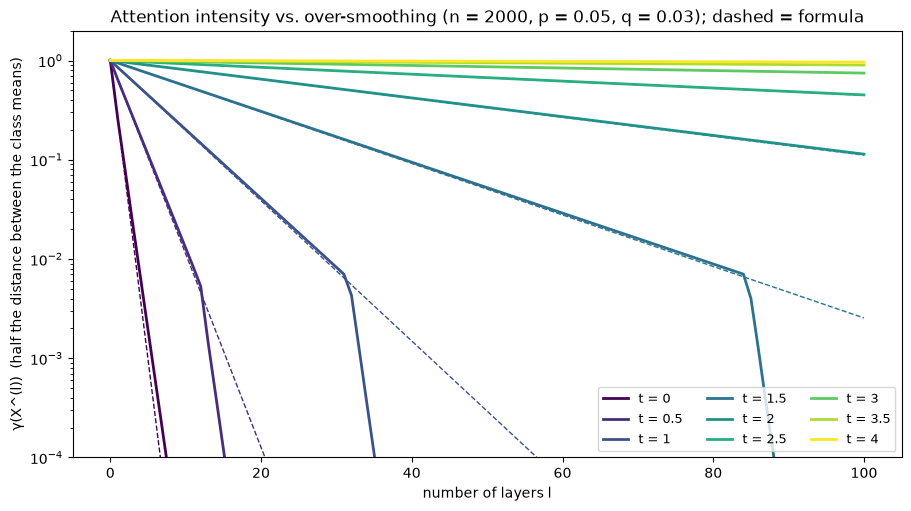

In [28]:
def intensity_attention(x, edge_index, t):
    """Parameter-free attention layer with intensity t (1-D features):
       α_ij ∝ exp(t · sign(x_i) sign(x_j)) over j ∈ N(i),    x_i' = Σ_j α_ij x_j"""
    s, d = edge_index
    sgn = torch.sign(x[:, 0])
    # ★ KEY: t = 0 is a GCN (mean aggregation); t > 0 favours the neighbours that look like node i.
    alpha = edge_softmax(t * sgn[d] * sgn[s], d, x.size(0))
    return scatter_sum(alpha[:, None] * x[s], d, x.size(0))

def class_distance(x, labels):
    """γ(X): half the distance between the two class means."""
    return ((x[labels == 0, 0].mean() - x[labels == 1, 0].mean()) / 2).item()

def sign_accuracy(x, labels):
    """Accuracy of the parameter-free classifier ŷ_i = C0 if x_i > 0 else C1."""
    return accuracy((x[:, 0] < 0).long(), labels)

# Over-smoothing: high SNR, 100 layers, several intensities t
n_m, p_m, q_m = 2000, 0.05, 0.03
Xm, ym, eim = csbm(n_m, p_m, q_m, mu=1.0, sigma=0.2, seed=0)
ts = [0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4]
layers = np.arange(101)
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
cmap = plt.get_cmap('viridis')
for idx, t in enumerate(ts):
    x, gam = Xm.clone(), []
    for l in layers:
        gam.append(class_distance(x, ym))
        x = intensity_attention(x, eim, t)
    theory = gam[0] * (1 - 2 * q_m / (p_m * math.exp(2 * t) + q_m)) ** layers
    color = cmap(idx / (len(ts) - 1))
    ax.plot(layers, np.clip(gam, 1e-6, None), color=color, lw=2, label=f't = {t}')
    ax.plot(layers, theory, color=color, lw=1, ls='--')
ax.set(yscale='log', ylim=(1e-4, 2), xlabel='number of layers l', ylabel='γ(X^(l))  (half the distance between the class means)',
       title=f'Attention intensity vs. over-smoothing (n = {n_m}, p = {p_m}, q = {q_m}); dashed = formula')
ax.legend(ncol=3, fontsize=9)
plt.show()

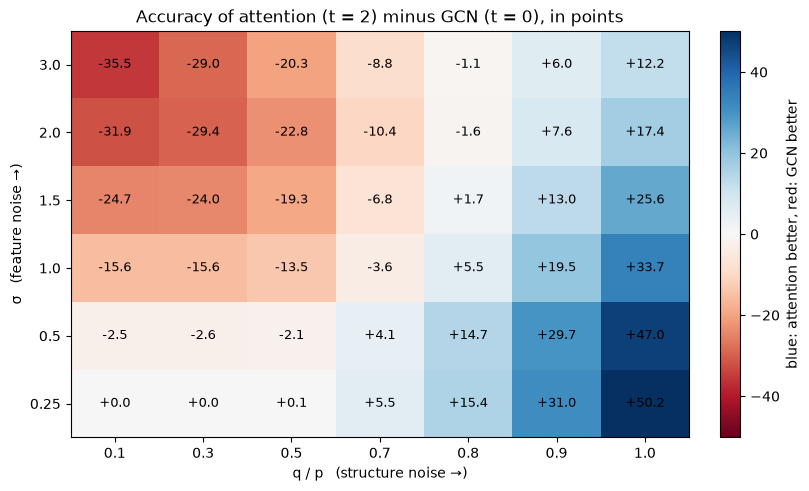

In [29]:
# Structure noise vs. feature noise: one layer, attention (t = 2) minus GCN (t = 0)
ratios = [0.1, 0.3, 0.5, 0.7, 0.8, 0.9, 1.0]           # q / p: structure noise
sigmas = [0.25, 0.5, 1.0, 1.5, 2.0, 3.0]                # σ (with μ = 1): feature noise
gain = np.zeros((len(sigmas), len(ratios)))
for a_i, sig in enumerate(sigmas):
    for b_i, r in enumerate(ratios):
        Xm, ym, eim = csbm(2000, 0.05, r * 0.05, mu=1.0, sigma=sig, seed=1)
        gain[a_i, b_i] = sign_accuracy(intensity_attention(Xm, eim, 2.0), ym) - sign_accuracy(intensity_attention(Xm, eim, 0.0), ym)

fig, ax = plt.subplots(figsize=(8, 4.8), constrained_layout=True)
lim = np.abs(gain).max() * 100
im = ax.imshow(gain * 100, cmap='RdBu', vmin=-lim, vmax=lim, origin='lower', aspect='auto')
for a_i in range(len(sigmas)):
    for b_i in range(len(ratios)):
        ax.text(b_i, a_i, f'{gain[a_i, b_i]*100:+.1f}', ha='center', va='center', fontsize=9)
ax.set(xticks=range(len(ratios)), xticklabels=ratios, yticks=range(len(sigmas)), yticklabels=sigmas,
       xlabel='q / p   (structure noise →)', ylabel='σ   (feature noise →)',
       title='Accuracy of attention (t = 2) minus GCN (t = 0), in points')
fig.colorbar(im, ax=ax, label='blue: attention better, red: GCN better')
plt.show()

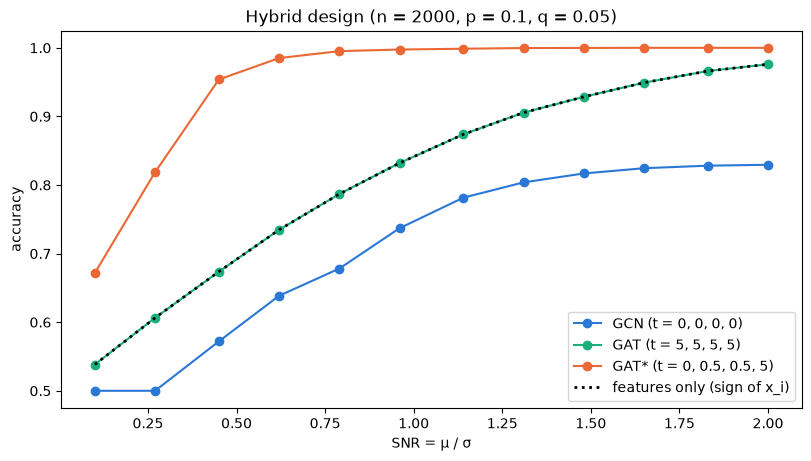

SNR 0.10: GCN (t = 0, 0, 0, 0) 0.500 | GAT (t = 5, 5, 5, 5) 0.538 | GAT* (t = 0, 0.5, 0.5, 5) 0.672 | features only 0.538
SNR 0.62: GCN (t = 0, 0, 0, 0) 0.639 | GAT (t = 5, 5, 5, 5) 0.735 | GAT* (t = 0, 0.5, 0.5, 5) 0.985 | features only 0.735
SNR 1.14: GCN (t = 0, 0, 0, 0) 0.782 | GAT (t = 5, 5, 5, 5) 0.874 | GAT* (t = 0, 0.5, 0.5, 5) 0.999 | features only 0.874
SNR 2.00: GCN (t = 0, 0, 0, 0) 0.830 | GAT (t = 5, 5, 5, 5) 0.976 | GAT* (t = 0, 0.5, 0.5, 5) 1.000 | features only 0.976


In [30]:
# Hybrid: 4 layers; t = 0 first to denoise, then increasing t to stop over-smoothing
schedules = {'GCN (t = 0, 0, 0, 0)': [0, 0, 0, 0], 'GAT (t = 5, 5, 5, 5)': [5, 5, 5, 5], 'GAT* (t = 0, 0.5, 0.5, 5)': [0, 0.5, 0.5, 5]}
snrs = np.round(np.linspace(0.1, 2.0, 12), 2)
hybrid = {name: [] for name in list(schedules) + ['features only']}
for snr in snrs:
    accs = {name: [] for name in hybrid}
    for seed in range(3):
        Xm, ym, eim = csbm(2000, 0.1, 0.05, mu=snr, sigma=1.0, seed=seed)
        accs['features only'].append(sign_accuracy(Xm, ym))
        for name, schedule in schedules.items():
            x = Xm
            for t in schedule:
                x = intensity_attention(x, eim, t)
            accs[name].append(sign_accuracy(x, ym))
    for name in hybrid:
        hybrid[name].append(np.mean(accs[name]))

fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
for (name, accs), color in zip(hybrid.items(), [COLORS['GCN'], COLORS['GATv2'], COLORS['GAT'], 'black']):
    if name == 'features only':
        ax.plot(snrs, accs, ':', color=color, lw=2, zorder=3, label='features only (sign of x_i)')
    else:
        ax.plot(snrs, accs, 'o-', color=color, label=name)
ax.set(xlabel='SNR = μ / σ', ylabel='accuracy', title='Hybrid design (n = 2000, p = 0.1, q = 0.05)')
ax.legend()
plt.show()
for i in [0, 3, 6, 11]:
    print(f'SNR {snrs[i]:.2f}: ' + ' | '.join(f'{name} {hybrid[name][i]:.3f}' for name in hybrid))

* Over-smoothing.
  * The measured class distance follows $\big(1-\frac{2q}{pe^{2t}+q}\big)^l$ almost exactly as long as the classes are well separated.
  * With $t=0$ (a GCN), the distance shrinks by a factor of 4 per layer ($\frac{p-q}{p+q}=0.25$) and vanishes after about 8 layers. With $t=3$, 74% of it is left after 100 layers, and with $t=4$, 96%.
  * The formula assumes that $\mathrm{sign}(x_i)$ is the class of node $i$. Once $\gamma$ becomes small compared with the spread inside a class (around $10^{-2}$ here), the signs are no longer reliable. The attention then stops favouring same-class neighbours, and $\gamma$ collapses faster than predicted.
* Structure noise vs. feature noise.
  * Attention wins (blue) when the structure is noisy ($q/p\to1$) and the features are clean (small $\sigma$): it uses the features to discard the wrong neighbours.
  * GCN wins (red) when the structure is reliable and the features are noisy. A node whose feature has the wrong sign then attends to the neighbours that share its wrong sign, while the plain average over many neighbours corrects the sign.
* GAT\*.
  * GAT with $t=5$ in every layer has exactly the accuracy of the features alone (the two curves coincide): every node only averages neighbours of its own sign, so no sign ever changes.
  * The 4-layer GCN denoises, but it also over-smooths: at low SNR every node ends with the same sign (50%).
  * GAT\* first applies one GCN layer, which raises the SNR, then increases $t$, which stops the smoothing. It is the best schedule at every SNR, e.g. 98.5% at SNR 0.62 vs. 73.5% (GAT) and 63.9% (GCN).

## 5.4. Are GATs out of balance? (Mustafa et al.)

The GAT layer with shared weights $W=W_s=W_t$, one head and a positively homogeneous activation $\phi=$ ReLU:

$$h_v^{l} = \phi\Big(\sum_{u\in\mathcal N(v)}\alpha^{l}_{uv}\,W^{l}h_u^{l-1}\Big),\qquad \alpha^{l}_{uv}=\mathrm{softmax}_u\big(\mathbf a^{l\top}\,\mathrm{LeakyReLU}(W^{l}h_u^{l-1}+W^{l}h_v^{l-1})\big).$$

For every hidden neuron $i$ of layer $l$, the gradients satisfy

$$\delta_i = \langle W^{l}[i,:],\nabla_{W^{l}[i,:]}\mathcal L\rangle - a^{l}[i]\,\nabla_{a^{l}[i]}\mathcal L - \langle W^{l+1}[:,i],\nabla_{W^{l+1}[:,i]}\mathcal L\rangle = 0 .$$

Under gradient flow this gives a conserved quantity:

$$c_i = \|W^{l}[i,:]\|^2 - \big(a^{l}[i]\big)^2 - \|W^{l+1}[:,i]\|^2 = \text{constant during training}.$$

Xavier initialisation starts with $c_i\neq 0$ (unbalanced). Balanced initialisation sets $\mathbf a=0$ and rescales the outgoing weights so that $c_i=0$. BalX starts from Xavier; BalO starts from a looks-linear orthogonal matrix $\begin{bmatrix}U&-U\\-U&U\end{bmatrix}$, so the network starts out acting linearly ($\mathrm{ReLU}(v)-\mathrm{ReLU}(-v)=v$).

In [31]:
class BalGATLayer(nn.Module):
    """GAT with shared weights W = W_s = W_t, one head and no bias."""
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.W = nn.Linear(in_dim, out_dim, bias=False)
        self.a = nn.Parameter(torch.empty(out_dim))

    def forward(self, h, edge_index):
        N = h.size(0)
        src, dst = edge_index
        z = self.W(h)
        e = (F.leaky_relu(z[src] + z[dst], 0.2) * self.a).sum(-1)
        return scatter_sum(edge_softmax(e, dst, N)[:, None] * z[src], dst, N)

class DeepGAT(nn.Module):
    """L stacked BalGATLayers with ReLU in between; init in {'xavier', 'balx', 'balo'}."""
    def __init__(self, in_dim, hidden_dim, out_dim, num_layers, init='xavier'):
        super().__init__()
        dims = [in_dim] + [hidden_dim] * (num_layers - 1) + [out_dim]
        self.layers = nn.ModuleList([BalGATLayer(dims[l], dims[l + 1]) for l in range(num_layers)])
        initialize_(self, init)

    def forward(self, x, edge_index):
        edge_index = add_self_loops(edge_index, x.size(0))
        for l, layer in enumerate(self.layers):
            x = layer(x, edge_index)
            if l < len(self.layers) - 1:
                x = F.relu(x)
        return x

@torch.no_grad()
def looks_linear_orthogonal_(W, first, last):
    """[U; -U] (first layer), [U, -U] (last layer) or [[U, -U], [-U, U]] (hidden layers) with orthogonal U."""
    n_out, n_in = W.shape
    if first:
        U = nn.init.orthogonal_(torch.empty(n_out // 2, n_in)); W.copy_(torch.cat([U, -U], 0))
    elif last:
        U = nn.init.orthogonal_(torch.empty(n_out, n_in // 2)); W.copy_(torch.cat([U, -U], 1))
    else:
        U = nn.init.orthogonal_(torch.empty(n_out // 2, n_in // 2))
        W.copy_(torch.cat([torch.cat([U, -U], 1), torch.cat([-U, U], 1)], 0))

@torch.no_grad()
def balance_(model):
    """a^l = 0, then for l = 1, 2, ...: rescale the outgoing weights of every neuron i of layer l so that
    ||W^{l+1}[:, i]|| = ||W^l[i, :]||, which gives c_i = 0 for every hidden neuron."""
    for layer in model.layers:
        layer.a.zero_()
    for l in range(len(model.layers) - 1):
        W_in, W_out = model.layers[l].W.weight, model.layers[l + 1].W.weight     # [n_l, n_{l-1}], [n_{l+1}, n_l]
        # ★ KEY: Balancing = equal incoming and outgoing norms for every neuron (and a = 0).
        W_out.mul_((W_in.norm(dim=1) / W_out.norm(dim=0).clamp_min(1e-12))[None, :])

def initialize_(model, init):
    L = len(model.layers)
    for l, layer in enumerate(model.layers):
        if init == 'balo':
            looks_linear_orthogonal_(layer.W.weight, first=(l == 0), last=(l == L - 1))
        else:
            glorot_(layer.W.weight)
        glorot_(layer.a.data.view(1, -1))
    if init in ('balx', 'balo'):
        balance_(model)

def conserved(model):
    """c_i = ||W^l[i,:]||² - a^l[i]² - ||W^{l+1}[:,i]||² for every hidden neuron, one tensor per hidden layer."""
    return [(m.W.weight.pow(2).sum(1) - m.a.pow(2) - m_next.W.weight.pow(2).sum(0)).detach()
            for m, m_next in zip(model.layers[:-1], model.layers[1:])]

def gradient_identity(model):
    """δ_i for every hidden neuron (call after loss.backward())."""
    return [((m.W.weight * m.W.weight.grad).sum(1) - m.a * m.a.grad - (m_next.W.weight * m_next.W.weight.grad).sum(0)).detach()
            for m, m_next in zip(model.layers[:-1], model.layers[1:])]

hidden layer 1: max |δ_i| = 2.2e-11   (size of the terms: 9.9e-05)
hidden layer 2: max |δ_i| = 4.4e-11   (size of the terms: 1.5e-04)
Xavier + GD   | loss 1.946 -> 0.817 | ||W^1||²: 122.9 -> 193.6 | mean |c_i| at the start: 0.827 | max |c_i(end) - c_i(start)|: 0.0028
Xavier + Adam | loss 1.946 -> 0.000 | ||W^1||²: 122.9 -> 5281.0 | mean |c_i| at the start: 0.827 | max |c_i(end) - c_i(start)|: 88.4815
BalX + GD     | loss 1.946 -> 0.064 | ||W^1||²: 122.9 -> 282.7 | mean |c_i| at the start: 0.000 | max |c_i(end) - c_i(start)|: 0.0081


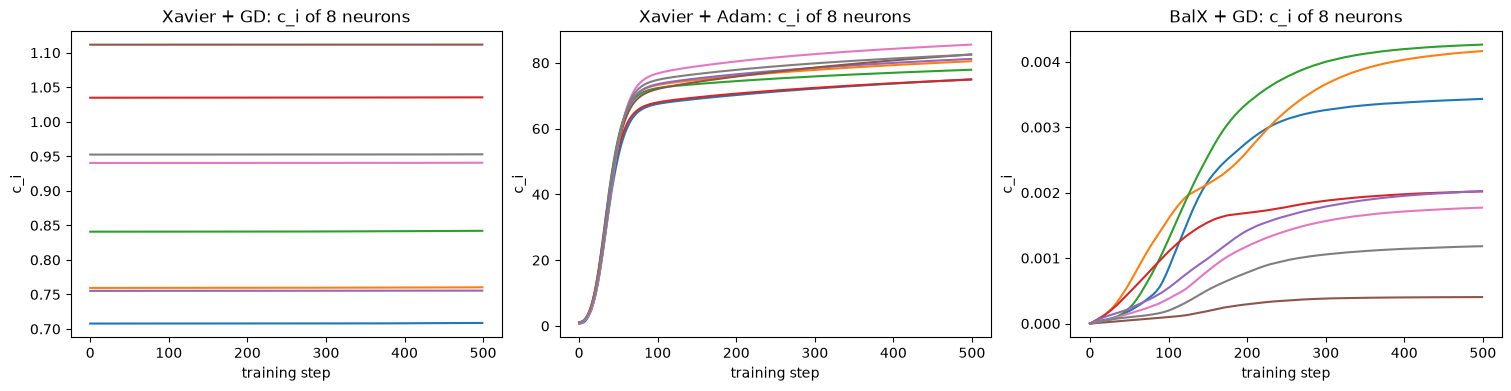

In [32]:
tr_mask = split[0]

# (1) The gradient identity holds exactly (up to float precision) for any weights
set_seed(0)
model = DeepGAT(num_features, 64, num_classes, num_layers=3).to(device)
F.cross_entropy(model(X, edge_index)[tr_mask], y[tr_mask]).backward()
for l, delta in enumerate(gradient_identity(model), start=1):
    term = (model.layers[l - 1].W.weight * model.layers[l - 1].W.weight.grad).sum(1).abs().max().item()
    print(f'hidden layer {l}: max |δ_i| = {delta.abs().max().item():.1e}   (size of the terms: {term:.1e})')

# (2) c_i during training: constant under gradient descent, drifts with Adam; 0 with a balanced initialisation
runs = {'Xavier + GD': ('xavier', 'gd'), 'Xavier + Adam': ('xavier', 'adam'), 'BalX + GD': ('balx', 'gd')}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), constrained_layout=True)
for ax, (title, (init, opt_name)) in zip(axes, runs.items()):
    set_seed(0)
    model = DeepGAT(num_features, 64, num_classes, num_layers=3, init=init).to(device)
    optimizer = (torch.optim.SGD(model.parameters(), lr=0.5) if opt_name == 'gd'
                 else torch.optim.Adam(model.parameters(), lr=0.005))
    norm_start, c_start = model.layers[0].W.weight.pow(2).sum().item(), torch.cat(conserved(model))
    history, losses = [], []
    for step in range(500):
        history.append(conserved(model)[0][:8].cpu())                # 8 neurons of hidden layer 1
        optimizer.zero_grad()
        loss = F.cross_entropy(model(X, edge_index)[tr_mask], y[tr_mask])
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    c_end = torch.cat(conserved(model))
    ax.plot(torch.stack(history).numpy())
    ax.set(title=f'{title}: c_i of 8 neurons', xlabel='training step', ylabel='c_i')
    print(f'{title:<14}| loss {losses[0]:.3f} -> {losses[-1]:.3f} | ||W^1||²: {norm_start:.1f} -> '
          f'{model.layers[0].W.weight.pow(2).sum().item():.1f} | mean |c_i| at the start: {c_start.abs().mean():.3f} '
          f'| max |c_i(end) - c_i(start)|: {(c_end - c_start).abs().max():.4f}')
plt.show()

* Gradient identity. $\delta_i$ is $10^{-11}$, while each of its terms is about $10^{-4}$: the identity holds up to rounding errors.
* Gradient descent. The values $c_i$ stay constant (largest change 0.003) although the weights move a lot ($\|W^1\|^2$ grows from 123 to 194): this is the conservation law. The small remaining drift is the discretisation error of a finite learning rate, since gradient descent only approximates gradient flow.
* Adam. Adam rescales every gradient coordinate separately, so it does not follow gradient flow: $c_i$ is not conserved and grows to about 80.
* Balanced start. From a balanced initialisation (BalX), $c_i$ starts at 0 and stays within 0.01 of it.

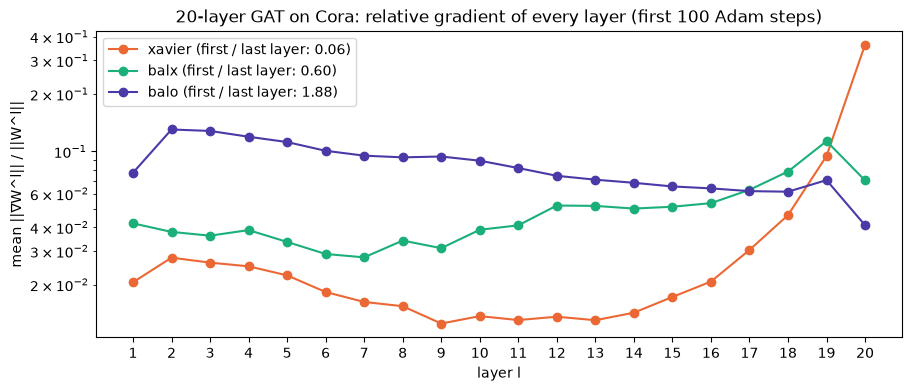

In [33]:
# (3) Relative gradient norms ||∇W^l|| / ||W^l|| of a 20-layer GAT during the first 100 Adam steps
fig, ax = plt.subplots(figsize=(9, 3.8), constrained_layout=True)
for init, color in [('xavier', COLORS['GAT']), ('balx', COLORS['GATv2']), ('balo', COLORS['SuperGAT'])]:
    set_seed(0)
    model = DeepGAT(num_features, 64, num_classes, num_layers=20, init=init).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.005)
    rel = []
    for step in range(100):
        optimizer.zero_grad()
        F.cross_entropy(model(X, edge_index)[tr_mask], y[tr_mask]).backward()
        rel.append([(m.W.weight.grad.norm() / m.W.weight.norm()).item() for m in model.layers])
        optimizer.step()
    rel = np.mean(rel, axis=0)
    ax.plot(range(1, 21), rel, 'o-', color=color, label=f'{init} (first / last layer: {rel[0] / rel[-1]:.2f})')
ax.set(yscale='log', xticks=range(1, 21), xlabel='layer l', ylabel='mean ||∇W^l|| / ||W^l||',
       title='20-layer GAT on Cora: relative gradient of every layer (first 100 Adam steps)')
ax.legend()
plt.show()

L =  2 | xavier: 80.0% | balx: 80.4% | balo: 81.4%
L =  5 | xavier: 76.0% | balx: 77.6% | balo: 80.9%
L = 10 | xavier: 73.4% | balx: 76.9% | balo: 80.7%
L = 20 | xavier: 46.9% | balx: 49.2% | balo: 74.3%


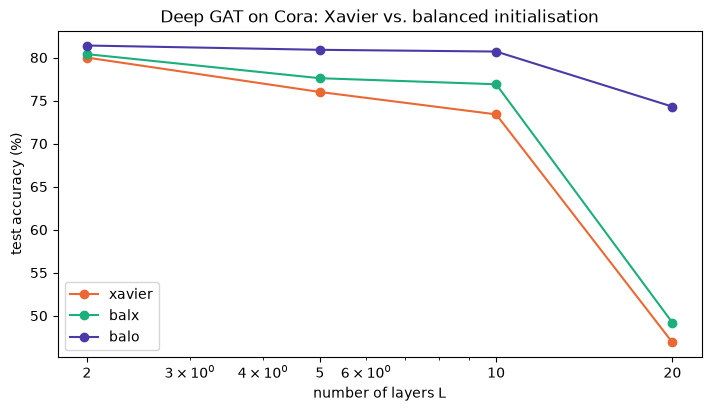

In [34]:
# (4) Test accuracy vs. depth (Adam, lr 0.005, no dropout / weight decay)
depths = [2, 5, 10, 20]
depth_acc = {init: [] for init in ['xavier', 'balx', 'balo']}
for L in depths:
    for init in depth_acc:
        set_seed(0)
        model = DeepGAT(num_features, 64, num_classes, num_layers=L, init=init)
        _, acc = train_model(model, (X, edge_index), epochs=1000, patience=300, lr=0.005, weight_decay=0.0)
        depth_acc[init].append(acc)
    print(f'L = {L:>2} | ' + ' | '.join(f'{init}: {depth_acc[init][-1]*100:.1f}%' for init in depth_acc))

fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
for (init, accs), color in zip(depth_acc.items(), [COLORS['GAT'], COLORS['GATv2'], COLORS['SuperGAT']]):
    ax.plot(depths, np.array(accs) * 100, 'o-', color=color, label=init)
ax.set(xscale='log', xticks=depths, xticklabels=depths, xlabel='number of layers L', ylabel='test accuracy (%)',
       title='Deep GAT on Cora: Xavier vs. balanced initialisation')
ax.legend()
plt.show()

* Relative gradients.
  * With Xavier, the last layer receives a relative gradient about 17 times larger than the first layer (ratio 0.06), and the layers in the middle receive the smallest. The early layers hardly move: this is the trainability bottleneck.
  * BalX narrows the gap (ratio 0.51). BalO gives a flat profile (ratio 1.9) with larger relative gradients in every layer except the last.
* Depth.
  * With 2 layers the three initialisations are equivalent (80–81%).
  * Xavier degrades with depth and collapses at 20 layers (46.9%). BalX helps (49.2%), and BalO keeps 74.3% at 20 layers.
  * The conservation law explains why the starting point matters: $c$ is fixed at initialisation, so a network that starts out unbalanced stays unbalanced for the whole of training.

# 6. Attention in other graph settings
## 6.1. FAGCN: signed attention

GAT's coefficients are positive and sum to 1, so a GAT layer always computes a weighted average of the neighbours: a low-pass filter that pulls neighbours together. FAGCN's self-gating coefficient can be negative:

$$\alpha^G_{ij}=\tanh\big(\mathbf g^\top[h_i\,\|\,h_j]\big)\in(-1,1),\qquad h_i^{(l)} = \varepsilon\, h_i^{(0)} + \sum_{j\in\mathcal N(i)}\frac{\alpha^G_{ij}}{\sqrt{d_id_j}}\,h_j^{(l-1)},\qquad h^{(0)}=\phi(W_1x),\quad h_{out} = W_2h^{(L)} .$$

$\alpha^G_{ij}>0$ adds the neighbour (low frequency, similar nodes); $\alpha^G_{ij}<0$ subtracts it (high frequency, pushes dissimilar nodes apart, useful under heterophily). Compare the models on Cora and on the heterophilous Texas graph (first 3 of the 10 standard 48/32/20 splits).

In [35]:
class FAGCN(nn.Module):
    """FAGCN (Bo et al., AAAI 2021) on the edge list (no self-loops: the ε h^(0) term plays that role)."""
    def __init__(self, in_dim, hidden_dim, out_dim, num_layers=2, eps=0.3, dropout=0.5):
        super().__init__()
        self.lin_in, self.lin_out = nn.Linear(in_dim, hidden_dim), nn.Linear(hidden_dim, out_dim)
        self.gates = nn.ModuleList([nn.Linear(2 * hidden_dim, 1) for _ in range(num_layers)])   # g of every layer
        self.eps, self.dropout = eps, dropout

    def forward(self, x, edge_index):
        N = x.size(0)
        src, dst = edge_index
        d = degree(dst, N).clamp(min=1)
        norm = (d[src] * d[dst]).rsqrt()                                     # 1 / sqrt(d_i d_j)
        x = F.dropout(x, self.dropout, self.training)
        h0 = F.dropout(F.relu(self.lin_in(x)), self.dropout, self.training)  # h^(0) = φ(W_1 x)
        h = h0
        for gate in self.gates:
            # ★ KEY: A signed coefficient per edge: > 0 adds the neighbour (low-pass), < 0 subtracts it (high-pass).
            a = torch.tanh(gate(torch.cat([h[dst], h[src]], dim=1))).squeeze(-1)
            self.alpha = a.detach()
            w = F.dropout(a * norm, self.dropout, self.training)
            # ★ KEY: The initial representation ε h^(0) is added back in every layer.
            h = self.eps * h0 + scatter_sum(w[:, None] * h[src], dst, N)
        return self.lin_out(h)

with contextlib.redirect_stderr(io.StringIO()):
    texas = WebKB(ROOT, "Texas")[0]
ei_tx = torch.cat([texas.edge_index, texas.edge_index.flip(0)], dim=1)
ei_tx = torch.unique(ei_tx[:, ei_tx[0] != ei_tx[1]], dim=1).to(device)      # undirected, no self-loops
X_tx = texas.x.to(device)
X_tx = X_tx / X_tx.sum(dim=1, keepdim=True).clamp(min=1)
y_tx = texas.y.to(device)
splits_tx = [tuple(m[:, s].to(device) for m in (texas.train_mask, texas.val_mask, texas.test_mask)) for s in range(3)]
print(f'Texas: {texas.num_nodes} nodes | {ei_tx.size(1) // 2} undirected edges | {X_tx.size(1)} features | '
      f'{int(y_tx.max()) + 1} classes | edge homophily {(y_tx[ei_tx[0]] == y_tx[ei_tx[1]]).float().mean():.2f}')

benchmark('FAGCN', lambda: FAGCN(num_features, 64, num_classes), lr=0.01, weight_decay=1e-3)
tx_models = {
    'MLP':   (lambda: MLP(X_tx.size(1), 64, 5), dict(lr=0.01)),
    'GCN':   (lambda: GCN(X_tx.size(1), 64, 5), dict(lr=0.01)),
    'GAT':   (lambda: GAT(X_tx.size(1), 8, 5), dict(lr=0.005)),
    'GATv2': (lambda: GAT(X_tx.size(1), 8, 5, layer=GATv2Layer), dict(lr=0.005)),
    'FAGCN': (lambda: FAGCN(X_tx.size(1), 64, 5), dict(lr=0.01, weight_decay=1e-3)),
}
for name, (make_model, kwargs) in tx_models.items():
    accs = []
    for s, sp in enumerate(splits_tx):
        set_seed(s)
        accs.append(train_model(make_model(), (X_tx, ei_tx), split=sp, labels=y_tx, **kwargs)[1])
    print(f'Texas | {name:<6} | Test Acc: {np.mean(accs)*100:.1f} ± {np.std(accs)*100:.1f}')

Texas: 183 nodes | 279 undirected edges | 1703 features | 5 classes | edge homophily 0.06
FAGCN                  | Test Acc: 82.07 ± 0.21
Texas | MLP    | Test Acc: 80.2 ± 4.6
Texas | GCN    | Test Acc: 63.1 ± 4.6
Texas | GAT    | Test Acc: 55.9 ± 5.6
Texas | GATv2  | Test Acc: 56.8 ± 4.4
Texas | FAGCN  | Test Acc: 73.9 ± 2.5


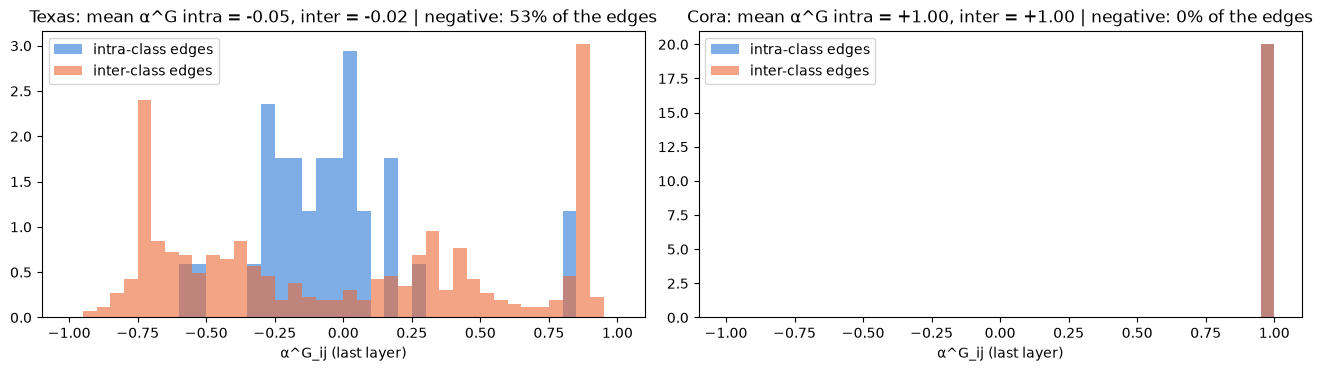

In [36]:
# Learned FAGCN coefficients α^G_ij of the last layer on intra- and inter-class edges
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), constrained_layout=True)
for ax, (name, x_g, ei_g, y_g, sp) in zip(axes, [('Texas', X_tx, ei_tx, y_tx, splits_tx[0]), ('Cora', X, edge_index, y, split)]):
    set_seed(0)
    model = FAGCN(x_g.size(1), 64, int(y_g.max()) + 1)
    train_model(model, (x_g, ei_g), split=sp, labels=y_g, lr=0.01, weight_decay=1e-3)
    model.eval()
    with torch.no_grad():
        model(x_g, ei_g)
    a = model.alpha.cpu().numpy()
    same = (y_g[ei_g[0]] == y_g[ei_g[1]]).cpu().numpy()
    ax.hist(a[same], bins=40, range=(-1, 1), alpha=0.6, density=True, color=COLORS['GCN'], label='intra-class edges')
    ax.hist(a[~same], bins=40, range=(-1, 1), alpha=0.6, density=True, color=COLORS['GAT'], label='inter-class edges')
    ax.set(title=f'{name}: mean α^G intra = {a[same].mean():+.2f}, inter = {a[~same].mean():+.2f} | '
                 f'negative: {(a < 0).mean() * 100:.0f}% of the edges', xlabel='α^G_ij (last layer)')
    ax.legend()
plt.show()

* Texas (edge homophily 0.06): every softmax-attention model is worse than the MLP that ignores the graph (GAT 55.9%, GATv2 56.8%, GCN 63.1% vs. MLP 80.2%). A convex combination of neighbours from other classes can only blur the node's own features. FAGCN (73.9%) is the best graph model: its $\varepsilon h^{(0)}$ term keeps the node's own representation, and negative coefficients let it subtract neighbours.
* The sign does not follow the classes. 53% of FAGCN's coefficients on Texas are negative, but their sign is unrelated to class agreement (mean +0.06 on intra-class vs. +0.07 on inter-class edges). The gate only sees the two endpoint representations.
* Cora: every coefficient saturates at +1, so FAGCN becomes a pure low-pass model, which is the right choice for a homophilous graph (82%).

## 6.2. HAN: attention on heterogeneous graphs

IMDB has three node types: movies (with bag-of-words features of their plot keywords), directors and actors. The task is to classify the movies into 3 genres (action, comedy, drama). Two meta-paths connect movies to movies:
* MDM (movie–director–movie): two movies with the same director,
* MAM (movie–actor–movie): two movies that share an actor.

HAN works hierarchically:
1. Type-specific projection: $h_i' = M_{\phi_i} h_i$.
2. Node-level attention per meta-path $\Phi$: $e^\Phi_{ij}=\mathrm{LeakyReLU}(\mathbf a_\Phi^\top[h_i'\,\|\,h_j'])$, $\alpha^\Phi_{ij}=\mathrm{softmax}_{j\in\mathcal N_i^\Phi}(e^\Phi_{ij})$, $z_i^\Phi=\big\Vert_{k=1}^K\sigma\big(\sum_j\alpha^{\Phi,k}_{ij}h_j'\big)$. This is a GAT on the meta-path graph.
3. Semantic-level attention: $w_\Phi=\frac{1}{|\mathcal V|}\sum_{i}\mathbf q^\top\tanh(W z_i^\Phi+b)$, $\beta_\Phi=\mathrm{softmax}_\Phi(w_\Phi)$, $Z=\sum_\Phi\beta_\Phi Z^\Phi$.
4. Prediction: a linear classifier on $Z$ with the cross-entropy over the labelled movies.

In [40]:
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile, is_zipfile


class CheckedIMDB(IMDB):
    def download(self):
        # Dropbox can return an HTML error page with a .zip filename.
        archive = Path(self.raw_dir) / 'IMDB_processed.zip'
        if not archive.exists() or not is_zipfile(archive):
            print('Downloading IMDB ...')
            try:
                with urlopen(self.url, timeout=60) as response:
                    payload = io.BytesIO(response.read())
                if not is_zipfile(payload):
                    raise ValueError('The server returned HTML or an invalid ZIP file.')
            except (OSError, ValueError) as exc:
                raise RuntimeError(
                    'IMDB download failed; the Dropbox link may be disabled. '
                    f'Place a valid IMDB_processed.zip at {archive.resolve()}, '
                    f'or put the six raw dataset files directly in {Path(self.raw_dir).resolve()}, '
                    'then rerun this cell. Retrying the cached HTML file cannot fix it.'
                ) from exc
            archive.write_bytes(payload.getvalue())

        # Copy only required files, accepting a nested IMDB_processed/ directory.
        with ZipFile(archive) as zipped:
            members = {}
            for name in self.raw_file_names:
                matches = [m for m in zipped.namelist() if Path(m).name == name]
                if len(matches) != 1:
                    raise RuntimeError(f'IMDB archive must contain exactly one {name}.')
                members[name] = matches[0]
            for name, member in members.items():
                (Path(self.raw_dir) / name).write_bytes(zipped.read(member))


imdb = CheckedIMDB(f'{ROOT}/IMDB')[0]
for node_type in imdb.node_types:
    print(f'{node_type:<9}: {imdb[node_type].num_nodes:>5} nodes, {imdb[node_type].x.size(1)} features')
for edge_type in imdb.edge_types:
    print(f'{" -> ".join(edge_type[::2]):<18}: {imdb[edge_type].edge_index.size(1):>6} edges')
y_imdb = imdb['movie'].y.to(device)
X_imdb = imdb['movie'].x.to(device)
split_imdb = tuple(imdb['movie'][m].to(device) for m in ('train_mask', 'val_mask', 'test_mask'))
C_imdb = int(y_imdb.max()) + 1
print(f'classes: {C_imdb} | train / val / test movies: {[int(m.sum()) for m in split_imdb]}')

movie    :  4278 nodes, 3066 features
director :  2081 nodes, 3066 features
actor    :  5257 nodes, 3066 features
movie -> director :   4278 edges
movie -> actor    :  12828 edges
director -> movie :   4278 edges
actor -> movie    :  12828 edges
classes: 3 | train / val / test movies: [400, 400, 3478]


In [41]:
def metapath_edges(*relations):
    """Edges of a meta-path: the product of the relation adjacency matrices, e.g. MDM = A_MD · A_DM.
    Each relation is (edge_index [2, E] from the source type to the target type, (n_source, n_target)).
    Returns the pairs (start node, end node) linked by at least one meta-path instance."""
    M = None
    for ei, shape in relations:
        R = torch.sparse_coo_tensor(ei, torch.ones(ei.size(1), device=ei.device), shape).coalesce()
        M = R if M is None else torch.sparse.mm(M, R).coalesce()
    return M.indices()

n_movie, n_director, n_actor = (imdb[t].num_nodes for t in ('movie', 'director', 'actor'))
rel = lambda s, t: imdb[s, 'to', t].edge_index.to(device)
metapaths = {
    'MDM': metapath_edges((rel('movie', 'director'), (n_movie, n_director)), (rel('director', 'movie'), (n_director, n_movie))),
    'MAM': metapath_edges((rel('movie', 'actor'), (n_movie, n_actor)), (rel('actor', 'movie'), (n_actor, n_movie))),
}
for name, ei in metapaths.items():
    nl = ei[:, ei[0] != ei[1]]
    print(f'{name}: {ei.size(1):>6} pairs (incl. the {int((ei[0] == ei[1]).sum())} self-pairs) | '
          f'mean degree {nl.size(1) / n_movie:.1f} | homophily {(y_imdb[nl[0]] == y_imdb[nl[1]]).float().mean():.2f}')

MDM:  17446 pairs (incl. the 4278 self-pairs) | mean degree 3.1 | homophily 0.61
MAM:  85358 pairs (incl. the 4278 self-pairs) | mean degree 19.0 | homophily 0.44


In [42]:
class HAN(nn.Module):
    """Heterogeneous graph Attention Network (Wang et al., WWW 2019) for one target node type.
    semantic_attention=False replaces the learned β_Φ by equal weights 1/P (an ablation)."""
    def __init__(self, in_dim, hidden_dim, out_dim, num_metapaths, heads=8, dropout=0.6, sem_dim=128,
                 semantic_attention=True):
        super().__init__()
        self.heads, self.hidden_dim, self.dropout = heads, hidden_dim, dropout
        self.semantic_attention = semantic_attention
        self.proj = nn.Linear(in_dim, heads * hidden_dim, bias=False)               # M_φ (type-specific projection)
        self.a_dst = nn.Parameter(torch.empty(num_metapaths, heads, hidden_dim))   # a_Φ = [a_dst || a_src] per meta-path
        self.a_src = nn.Parameter(torch.empty(num_metapaths, heads, hidden_dim))
        glorot_(self.proj.weight)
        for p in range(num_metapaths):
            glorot_(self.a_dst.data[p]); glorot_(self.a_src.data[p])
        self.sem_W = nn.Linear(heads * hidden_dim, sem_dim)                         # W, b of the semantic attention
        self.sem_q = nn.Linear(sem_dim, 1, bias=False)                              # q
        self.out = nn.Linear(heads * hidden_dim, out_dim)                           # classifier C

    def forward(self, x, metapath_edge_list):
        N = x.size(0)
        x = F.dropout(x, self.dropout, self.training)
        h = self.proj(x).view(N, self.heads, self.hidden_dim)                        # h_i' = M_φ h_i
        Z = []
        for p, (src, dst) in enumerate(metapath_edge_list):
            # ★ KEY: Node-level attention = a GAT on the meta-path graph, with its own attention vector a_Φ.
            e = F.leaky_relu((h[dst] * self.a_dst[p]).sum(-1) + (h[src] * self.a_src[p]).sum(-1), 0.2)
            alpha = F.dropout(edge_softmax(e, dst, N), self.dropout, self.training)
            Z.append(F.elu(scatter_sum(alpha.unsqueeze(-1) * h[src], dst, N).reshape(N, -1)))   # z_i^Φ
        Z = torch.stack(Z, dim=1)                                                    # [N, P, K·F']
        # ★ KEY: Semantic-level attention: one importance w_Φ per meta-path, averaged over all nodes.
        w = self.sem_q(torch.tanh(self.sem_W(Z))).mean(dim=0)                        # [P, 1]
        beta = torch.softmax(w, dim=0) if self.semantic_attention else torch.full_like(w, 1 / w.size(0))
        self.beta = beta.squeeze(-1).detach()
        z = (beta.unsqueeze(0) * Z).sum(dim=1)                                       # Z = Σ_Φ β_Φ Z^Φ
        return self.out(F.dropout(z, self.dropout, self.training))

def macro_f1(pred, labels, C):
    """Macro-F1: the F1 score of every class, averaged with equal weights."""
    f1 = []
    for c in range(C):
        tp = ((pred == c) & (labels == c)).sum().item()
        fp = ((pred == c) & (labels != c)).sum().item()
        fn = ((pred != c) & (labels == c)).sum().item()
        f1.append(2 * tp / max(2 * tp + fp + fn, 1))
    return float(np.mean(f1))

In [43]:
def evaluate_imdb(model, inputs):
    model.eval()
    with torch.no_grad():
        pred = model(*inputs).argmax(dim=1)
    te = split_imdb[2]
    return macro_f1(pred[te], y_imdb[te], C_imdb), accuracy(pred[te], y_imdb[te])

han_variants = {'HAN (MDM + MAM)': ['MDM', 'MAM'], 'GAT on MDM only': ['MDM'], 'GAT on MAM only': ['MAM']}
han_scores, han_beta = {}, None
for name, mp_names in han_variants.items():
    scores = []
    for seed in range(3):
        set_seed(seed)
        model = HAN(X_imdb.size(1), 8, C_imdb, len(mp_names))
        inputs = (X_imdb, [metapaths[m] for m in mp_names])
        train_model(model, inputs, split=split_imdb, labels=y_imdb, lr=0.005, weight_decay=1e-3)
        scores.append(evaluate_imdb(model, inputs))
        if name.startswith('HAN') and seed == 0:
            han_beta = model.beta.cpu().numpy()
    han_scores[name] = np.array(scores)
scores = []
for seed in range(3):
    set_seed(seed)
    model = MLP(X_imdb.size(1), 64, C_imdb)
    train_model(model, (X_imdb,), split=split_imdb, labels=y_imdb, lr=0.005, weight_decay=1e-3)
    scores.append(evaluate_imdb(model, (X_imdb,)))
han_scores['MLP (no graph)'] = np.array(scores)
for name, s in han_scores.items():
    print(f'IMDB | {name:<16} | Macro-F1 {s[:, 0].mean()*100:.2f} ± {s[:, 0].std()*100:.2f} | '
          f'Accuracy (= Micro-F1) {s[:, 1].mean()*100:.2f} ± {s[:, 1].std()*100:.2f}')
print(f'Semantic attention of HAN (seed 0): β_MDM = {han_beta[0]:.3f}, β_MAM = {han_beta[1]:.3f}')

IMDB | HAN (MDM + MAM)  | Macro-F1 58.25 ± 0.40 | Accuracy (= Micro-F1) 58.76 ± 0.43
IMDB | GAT on MDM only  | Macro-F1 54.74 ± 0.17 | Accuracy (= Micro-F1) 55.14 ± 0.06
IMDB | GAT on MAM only  | Macro-F1 49.01 ± 0.57 | Accuracy (= Micro-F1) 51.32 ± 0.62
IMDB | MLP (no graph)   | Macro-F1 49.09 ± 0.66 | Accuracy (= Micro-F1) 49.64 ± 0.48
Semantic attention of HAN (seed 0): β_MDM = 0.547, β_MAM = 0.453


HAN in PyTorch Geometric. `AddMetaPaths` builds the same two meta-path graphs and `HANConv` implements both attention levels (its hidden size of 128 is split over the 8 heads).

In [44]:
import torch_geometric.transforms as T
from torch_geometric.nn import HANConv

class PyGHAN(nn.Module):
    def __init__(self, metadata, out_channels, hidden_channels=128, heads=8):
        super().__init__()
        self.han_conv = HANConv(-1, hidden_channels, heads=heads, dropout=0.6, metadata=metadata)
        self.lin = nn.Linear(hidden_channels, out_channels)

    def forward(self, x_dict, edge_index_dict):
        return self.lin(self.han_conv(x_dict, edge_index_dict)['movie'])

imdb_mp = T.AddMetaPaths(metapaths=[[('movie', 'actor'), ('actor', 'movie')], [('movie', 'director'), ('director', 'movie')]],
                         drop_orig_edge_types=True, drop_unconnected_node_types=True)(imdb.clone()).to(device)
scores = []
for seed in range(3):
    set_seed(seed)
    model = PyGHAN(imdb_mp.metadata(), C_imdb).to(device)
    with torch.no_grad():
        model(imdb_mp.x_dict, imdb_mp.edge_index_dict)            # initialise the lazy (-1) input size
    inputs = (imdb_mp.x_dict, imdb_mp.edge_index_dict)
    train_model(model, inputs, split=split_imdb, labels=y_imdb, lr=0.005, weight_decay=1e-3)
    scores.append(evaluate_imdb(model, inputs))
scores = np.array(scores)
print(f'IMDB | PyG HANConv | Macro-F1 {scores[:, 0].mean()*100:.2f} ± {scores[:, 0].std()*100:.2f} | '
      f'Accuracy {scores[:, 1].mean()*100:.2f} ± {scores[:, 1].std()*100:.2f}')

IMDB | PyG HANConv | Macro-F1 55.96 ± 0.51 | Accuracy 56.75 ± 0.40


* Results. HAN is the best model (Macro-F1 58.25%). Combining the two meta-paths beats a GAT on either of them alone (MDM 54.74%, MAM 49.01%) and the MLP (49.09%).
* Semantic attention. HAN gives the larger weight to MDM ($\beta=0.56$ vs. 0.44 for MAM). Movies by the same director share their genre more often than movies that share an actor (homophily 0.61 vs. 0.44). On its own, MAM is no better than ignoring the graph.
* PyG's HANConv reaches 55.96%. The two implementations differ in their hyper-parameters: 8 heads × 8 features here vs. 128 features split over 8 heads, and our extra dropout on the inputs and before the classifier.

# 7. Summary

| Model | Attention score of an edge $j\to i$ | Key property |
|:--|:--|:--|
| GCN | $1/\sqrt{d_id_j}$ (fixed) | all neighbours equally important |
| GAT | $\mathrm{LeakyReLU}(\mathbf a_1^\top Wh_i+\mathbf a_2^\top Wh_j)$ | static: same ranking of the keys for every query |
| GATv2 | $\mathbf a^\top\mathrm{LeakyReLU}(W_th_i+W_sh_j)$ | dynamic: the ranking depends on the query |
| SuperGAT | GO / DP / SD / MX + edge loss $\mathcal L_{SS}$ | attention also encodes the graph structure |
| FAGCN | $\tanh(\mathbf g^\top[h_i\,\Vert\,h_j])\in(-1,1)$ | signed: low-pass and high-pass |
| HAN | node-level GAT per meta-path + semantic attention $\beta_\Phi$ | heterogeneous graphs |

Theory: attention helps when the features are informative enough to tell the edges apart, i.e. in the easy regime and under high structure noise. In the hard regime it collapses to uniform weights, so GAT ≈ GCN. Large attention intensities stop over-smoothing, and GAT\* uses GCN layers first and attention later. Deep GATs train much better from a balanced initialisation.

Test accuracies on Cora in this notebook:

Model                      Test accuracy (3 seeds)
MLP                                 58.80 ± 0.24
GCN                                 82.57 ± 0.26
GAT                                 82.10 ± 1.02
GATv2                               82.87 ± 0.33
GAT (8 output heads)                82.30 ± 0.24
SuperGAT-GO                         82.43 ± 0.21
SuperGAT-DP                         82.70 ± 0.28
SuperGAT-SD                         82.60 ± 0.36
SuperGAT-MX                         83.67 ± 0.40
FAGCN                               82.07 ± 0.21


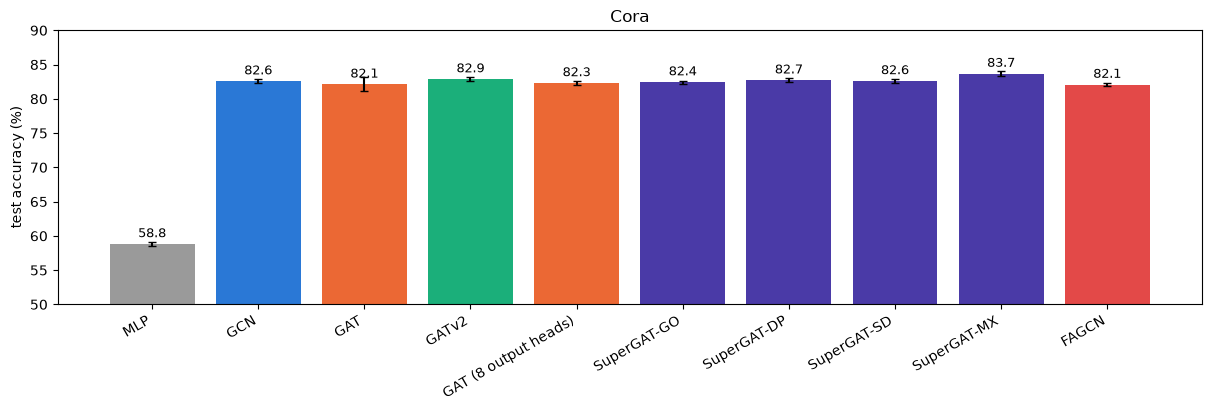

In [45]:
names = list(RESULTS)
print(f"{'Model':<24}{'Test accuracy (3 seeds)':>26}")
for name in names:
    print(f'{name:<24}{RESULTS[name].mean()*100:>17.2f} ± {RESULTS[name].std()*100:.2f}')

color_of = lambda n: COLORS.get(n, COLORS['SuperGAT'] if n.startswith('SuperGAT') else COLORS['GAT'])
fig, ax = plt.subplots(figsize=(12, 4), constrained_layout=True)
means = [RESULTS[n].mean() * 100 for n in names]
ax.bar(range(len(names)), means, yerr=[RESULTS[n].std() * 100 for n in names], capsize=3,
       color=[color_of(n) for n in names])
for i, m in enumerate(means):
    ax.text(i, m + 1, f'{m:.1f}', ha='center', fontsize=9)
ax.set(xticks=range(len(names)), ylim=(50, 90), ylabel='test accuracy (%)', title='Cora')
ax.set_xticklabels(names, rotation=30, ha='right')
plt.show()